# LAB 12 — Freight Cost Prediction PoC
## Stage 01-03: Business Framing, Dataset Qualification & Data Quality Audit

**Module:** LAB12 — End-to-End Freight Cost Prediction PoC (Stages 01–03 only)
**Audience:** LAB02-LAB11'i tamamlamış katılımcılar

Bu çalışma, 14 stage olarak planlanan LAB12 projesinin **yalnızca ilk üç stage'ini** kapsar:

- **Stage 01** — Business Understanding & Problem Framing
- **Stage 02** — Data Acquisition, Schema & Versioning
- **Stage 03** — Data Quality Audit & Dataset Qualification

Bu notebook'ta **model eğitimi, preprocessing, feature engineering veya train/test split
yapılmaz** -- bunlar sonraki stage'lerin konusudur. Mühendislik yaklaşımı:

**Hypothesis → Statistical Evidence → Comparative Analysis → Engineering Decision → Validation → Documentation**

İstatistiksel testler her kararın mutlak doğruluğunu ispatlamaz; kararlar Descriptive
Statistics, Statistical Diagnostics, Effect Sizes, Controlled Comparisons, Domain Constraints,
Data Availability ve Reproducibility ile desteklenir.

In [1]:
# Same environment setup pattern as LAB02-LAB11.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config  # noqa: E402

config = load_config()
lab12_cfg = config["lab12"]
RANDOM_SEED = config["random_seed"]
np.random.seed(RANDOM_SEED)
print("Project root:", PROJECT_ROOT)
print("lab12 config loaded:", list(lab12_cfg.keys()))

Project root: C:\Users\pc\ml-labs
lab12 config loaded: ['dataset', 'qualification', 'artifacts']


---

## Dosya Keşfi (Dataset Discovery)

Dosya adını **varsaymıyoruz** -- `data/freight_cost/` klasöründeki gerçek dosyaları listeleyip,
config'teki pattern ile eşleştiriyoruz.

In [2]:
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
if not dataset_dir.exists():
    raise FileNotFoundError(f"Expected dataset directory not found: {dataset_dir}")

all_files = sorted(dataset_dir.iterdir())
print("Files found in", dataset_dir, ":")
for f in all_files:
    print(" -", f.name, f"({f.stat().st_size:,} bytes)")

candidates = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
print("\nCandidates matching pattern", repr(lab12_cfg["dataset"]["filename_pattern"]), ":", [c.name for c in candidates])
if len(candidates) == 0:
    raise FileNotFoundError("No file matched the expected filename pattern.")
if len(candidates) > 1:
    raise ValueError(f"Multiple candidate files found -- refusing to silently pick one: {candidates}")

DATASET_PATH = candidates[0]
print("\nSelected main dataset file:", DATASET_PATH.name)
print("No separate data dictionary file was found in this folder -- a provisional data "
      "dictionary will be built from the schema itself (Section 2.3).")

Files found in C:\Users\pc\ml-labs\data\freight_cost :
 - SCMS_Delivery_History_Dataset_20150929.csv (3,819,612 bytes)

Candidates matching pattern 'SCMS_Delivery_History_Dataset*' : ['SCMS_Delivery_History_Dataset_20150929.csv']

Selected main dataset file: SCMS_Delivery_History_Dataset_20150929.csv
No separate data dictionary file was found in this folder -- a provisional data dictionary will be built from the schema itself (Section 2.3).


### Encoding & Delimiter Tespiti

UTF-8 başarısız olursa alternatif encoding'leri **kontrollü biçimde** deniyoruz -- hatalı
karakterleri sessizce değiştirmiyoruz.

In [3]:
def detect_encoding(path: Path, candidates: list) -> str:
    for enc in candidates:
        try:
            pd.read_csv(path, encoding=enc, nrows=5)
            return enc
        except UnicodeDecodeError:
            continue
    raise ValueError(f"None of the candidate encodings worked for {path}")


try:
    pd.read_csv(DATASET_PATH, encoding="utf-8", nrows=5)
    DETECTED_ENCODING = "utf-8"
except UnicodeDecodeError as e:
    print("utf-8 failed:", e)
    DETECTED_ENCODING = detect_encoding(DATASET_PATH, ["latin-1", "cp1252"])

print("Detected encoding:", DETECTED_ENCODING)
assert DETECTED_ENCODING == lab12_cfg["dataset"]["encoding"], "Detected encoding must match config."

with open(DATASET_PATH, "r", encoding=DETECTED_ENCODING) as f:
    first_line = f.readline()
DELIMITER = "," if first_line.count(",") > first_line.count(";") else ";"
print("Detected delimiter:", repr(DELIMITER))

utf-8 failed: 'utf-8' codec can't decode byte 0xf4 in position 1: invalid continuation byte
Detected encoding: latin-1
Detected delimiter: ','


In [4]:
df = pd.read_csv(DATASET_PATH, encoding=DETECTED_ENCODING, sep=DELIMITER)
print("shape:", df.shape)
print("\ncolumn names:")
for c in df.columns:
    print(" -", repr(c))
print("\nduplicate column names:", df.columns.duplicated().sum())

shape: (10324, 33)

column names:
 - 'ID'
 - 'Project Code'
 - 'PQ #'
 - 'PO / SO #'
 - 'ASN/DN #'
 - 'Country'
 - 'Managed By'
 - 'Fulfill Via'
 - 'Vendor INCO Term'
 - 'Shipment Mode'
 - 'PQ First Sent to Client Date'
 - 'PO Sent to Vendor Date'
 - 'Scheduled Delivery Date'
 - 'Delivered to Client Date'
 - 'Delivery Recorded Date'
 - 'Product Group'
 - 'Sub Classification'
 - 'Vendor'
 - 'Item Description'
 - 'Molecule/Test Type'
 - 'Brand'
 - 'Dosage'
 - 'Dosage Form'
 - 'Unit of Measure (Per Pack)'
 - 'Line Item Quantity'
 - 'Line Item Value'
 - 'Pack Price'
 - 'Unit Price'
 - 'Manufacturing Site'
 - 'First Line Designation'
 - 'Weight (Kilograms)'
 - 'Freight Cost (USD)'
 - 'Line Item Insurance (USD)'

duplicate column names: 0


**Doğrulama:** `Côte d'Ivoire` gibi aksanlı karakterler latin-1 ile doğru render ediliyor
mu (önceki oturumlarda terminal codepage'inden kaynaklı yanlış-pozitif bir "mojibake" izlenimi
oluşabiliyordu -- burada gerçek karakter kodlarını kontrol ediyoruz).

In [5]:
_sample_country = [c for c in df["Country"].unique() if "Ivoire" in str(c)][0]
print("Sample value:", _sample_country)
print("Character codepoints:", [hex(ord(ch)) for ch in _sample_country])
assert "ô" in _sample_country, "Expected the correctly-decoded 'ô' character (U+00F4)."
print("Encoding confirmed correct (not a mojibake replacement character).")

Sample value: Côte d'Ivoire
Character codepoints: ['0x43', '0xf4', '0x74', '0x65', '0x20', '0x64', '0x27', '0x49', '0x76', '0x6f', '0x69', '0x72', '0x65']
Encoding confirmed correct (not a mojibake replacement character).


---

# Stage 01 — Business Understanding & Problem Framing

## 1.1 Business Problem

**PoC Adı:** Freight Cost Prediction

**İş Problemi:** Sevkiyat öncesinde erişilebilir operasyonel bilgilerden yararlanarak,
gelecekteki bir sevkiyatın navlun maliyetini (USD) tahmin etmek.

**Main Objective:** Historical freight cost prediction.

**Out of Scope:** Freight Quote Optimization, Dynamic Pricing, Win Probability, Carrier Tender
Optimization, Route Optimization, Delivery Delay Prediction. Bunlar ilişkili problemler olsa da
bu PoC'un hedefi değildir.

## 1.2 Target Definition

Beklenen target kolonu: `Freight Cost (USD)`. Aşağıda bu kolonun gerçek değerlerini inceleyerek
yedi kritik soruyu yanıtlıyoruz -- varsayımla değil.

In [6]:
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
assert TARGET_COLUMN in df.columns, f"{TARGET_COLUMN} not found in columns."

raw_target = df[TARGET_COLUMN]
print("dtype:", raw_target.dtype, "(object -- confirms mixed numeric/text values)")
print("\nUnique non-numeric value samples (first 10 distinct):")
numeric_target_probe = pd.to_numeric(raw_target, errors="coerce")
non_numeric_values = raw_target[numeric_target_probe.isna()]
print(non_numeric_values.value_counts().head(10))

dtype: str (object -- confirms mixed numeric/text values)

Unique non-numeric value samples (first 10 distinct):
Freight Cost (USD)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
See DN-304 (ID#:10589)                  16
See ASN-32231 (ID#:13648)               14
See ASN-31750 (ID#:19272)               14
See ASN-28279 (ID#:13547)               13
See DN-3015 (ID#:82554)                 12
See ASN-26738 (ID#:15115)               10
See DN-2035 (ID#:82356)                 10
See DN-3561 (ID#:82654)                 10
Name: count, dtype: int64


### Yedi Kritik Sorunun Yanıtı (gerçek veriye dayanarak)

1. **Bu alan gerçekleşmiş taşıma maliyetini mi ifade ediyor?** Numeric olan satırlarda
   (aşağıda ölçülecek) evet görünüyor -- ancak bu "gerçekleşmiş/invoiced" ile "quoted/planned"
   ayrımını veri sözlüğü düzeyinde **doğrulayamıyoruz** (veri setinde bu ayrımı yapan ayrı bir
   alan yok). **Doğrulanmamış varsayım.**
2. **Ayrı faturalandırılan maliyetler bu alanda nasıl temsil ediliyor?** `"Invoiced
   Separately"` metin değeriyle -- sayısal bir tutar verilmiyor.
3. **Ürün bedeline dahil edilen navlunlar nasıl temsil ediliyor?** `"Freight Included in
   Commodity Cost"` metin değeriyle -- bu durumda navlun **yapısal olarak gözlenemez**, "eksik
   veri" değil, "ürün fiyatına gömülü" bir durumdur.
4. **Target farklı shipment line item'larında tekrar ediyor olabilir mi?** Aşağıda (Stage 2.4)
   somut olarak ölçülecek.
5. **Bu alan gerçekten shipment-level total freight cost'u temsil ediyor mu?** Stage 2.4'teki
   ASN/DN grup analizi ile ölçülecek.
6. **Bazı kayıtların target değerleri başka shipment kayıtlarına referans veriyor mu?**
   Yukarıdaki örnekte görüldüğü gibi evet -- `"See ASN-xxxx (ID#:yyyy)"` formatında.
7. **Freight cost ile freight selling price birbirinden ayrılabiliyor mu?** Veri setinde ayrı
   bir "selling price" alanı yok -- bu ayrım bu dataset'ten **doğrulanamıyor**.

### Critical Rule

Hedefin semantiği tam olarak doğrulanamadığından (özellikle Soru 1 ve 7), **kesin bir regression
target contract** henüz oluşturulmuyor -- bu, Stage 03'teki Qualification Gate kararına
taşınacak açık bir risktir.

## 1.3 Prediction Time Definition

**Önerilen tahmin anı:** Pre-Shipment Cost Estimation -- sevkiyat planlamasına ilişkin temel
bilgiler biliniyor, gerçek taşıma maliyeti henüz kesinleşmemiş.

In [7]:
feature_availability_rows = [
    {"Feature": "Destination Country (Country)", "Category": "Available", "Reason": "Known at planning time -- part of the order."},
    {"Feature": "Shipment Mode", "Category": "Conditionally Available", "Reason": "Likely planned, but 360 rows (3.5%) are missing -- availability itself is imperfect."},
    {"Feature": "Vendor INCO Term", "Category": "Available", "Reason": "A contractual term agreed at order time, before shipment."},
    {"Feature": "Product Group", "Category": "Available", "Reason": "Known from the order/product catalog."},
    {"Feature": "Line Item Quantity", "Category": "Available", "Reason": "Ordered quantity, known at planning time."},
    {"Feature": "Line Item Value", "Category": "Available", "Reason": "Ordered value, known at planning time."},
    {"Feature": "Weight (Kilograms)", "Category": "Unknown", "Reason": "Dataset does not distinguish a PLANNED weight from a MEASURED (post-packing) weight -- cannot verify prediction-time availability from this data alone."},
    {"Feature": "Vendor", "Category": "Available", "Reason": "Known at order/vendor-selection time."},
    {"Feature": "Manufacturing Site", "Category": "Conditionally Available", "Reason": "Usually known once a vendor/product is selected, but may not be finalized at the earliest planning point."},
    {"Feature": "Scheduled Delivery Date", "Category": "Conditionally Available", "Reason": "Planned date -- but the dataset does not confirm whether it is set before or alongside freight booking."},
    {"Feature": "PO Sent to Vendor Date / PQ First Sent to Client Date", "Category": "Conditionally Available", "Reason": "Planning-stage dates, but a large share contain sentinel placeholders (see Stage 2.5)."},
    {"Feature": "Delivered to Client Date / Delivery Recorded Date", "Category": "Unavailable", "Reason": "Outcome dates -- realized AFTER shipment, by definition not known at prediction time."},
    {"Feature": "Freight Cost (USD) itself", "Category": "Unavailable", "Reason": "This is the target -- never a feature."},
]
feature_availability_df = pd.DataFrame(feature_availability_rows)
feature_availability_df

,Feature,Category,Reason
0,Destination Country (Country),Available,Known at planning time -- part of the order.
1,Shipment Mode,Conditionally Available,"Likely planned, but 360 rows (3.5%) are missin..."
2,Vendor INCO Term,Available,"A contractual term agreed at order time, befor..."
3,Product Group,Available,Known from the order/product catalog.
4,Line Item Quantity,Available,"Ordered quantity, known at planning time."
5,Line Item Value,Available,"Ordered value, known at planning time."
6,Weight (Kilograms),Unknown,Dataset does not distinguish a PLANNED weight ...
7,Vendor,Available,Known at order/vendor-selection time.
8,Manufacturing Site,Conditionally Available,Usually known once a vendor/product is selecte...
9,Scheduled Delivery Date,Conditionally Available,Planned date -- but the dataset does not confi...


`Unknown` olarak sınıflandırılan alanlar (`Weight (Kilograms)`), varsayılan model girdisine
**dahil edilmeyecek** şekilde işaretlenmiştir -- bu karar Stage 03.5'te somut kanıtla
yeniden değerlendirilecektir.

## 1.4 Business Metrics & Success Criteria

Bu aşamada metrik **hesaplanmıyor** -- yalnızca tanımlar ve iş ilişkisi belirleniyor:

- **MAE (USD)** -- ortalama mutlak dolar hatası, iş birimi tarafından en kolay yorumlanabilir.
- **RMSE (USD)** -- büyük hatalara daha duyarlı.
- **WAPE** -- mümkün olduğunda (yüksek varyanslı target için MAE'nin toplam ölçeğe göre
  normalize edilmiş hâli).
- **R²** -- yalnızca destekleyici metrik, tek başlı başarı kriteri değil.
- **Median Absolute Error** -- aşırı değerlere (skewed distribution, bkz. Stage 3.3) daha
  dayanıklı.
- **High-Cost Segment MAE** -- yüksek maliyetli sevkiyatlarda performans ayrı izlenmeli (zira
  Stage 3.3'te güçlü sağa-çarpık bir dağılım bulunacaktır).

### Success Criteria (Pending Business Validation)

İş biriminden onaylanmış parasal tolerans değerleri **bulunmadığından**, kesin bir MAE
acceptance threshold **uydurulmamıştır** -- bu eşikler `Pending Business Validation` olarak
işaretlenmiştir. Başarı kriterleri; Baseline improvement, Average absolute dollar error,
High-cost shipment performance, Segment stability, Reproducibility ve Prediction-time validity
unsurlarını içermelidir -- yalnızca R² ile tanımlanmayacaktır.

---

# Stage 02 — Data Acquisition, Schema & Versioning

## 2.1 Dataset Fingerprinting

SHA-256, dosyayı tek seferde belleğe yüklemeden (chunk-based) hesaplanır.

In [8]:
def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


dataset_sha256 = calculate_file_hash(DATASET_PATH)
dataset_metadata = {
    "Dataset_Name": "SCMS Delivery History Dataset",
    "Source": "USAID / SCMS Delivery History (Kaggle: apoorvwatsky/supply-chain-shipment-pricing-data)",
    "Filename": DATASET_PATH.name,
    "SHA256": dataset_sha256,
    "File_Size_Bytes": DATASET_PATH.stat().st_size,
    "Row_Count": int(df.shape[0]),
    "Column_Count": int(df.shape[1]),
    "Encoding": DETECTED_ENCODING,
    "Delimiter": DELIMITER,
}
for k, v in dataset_metadata.items():
    print(f"{k}: {v}")

Dataset_Name: SCMS Delivery History Dataset
Source: USAID / SCMS Delivery History (Kaggle: apoorvwatsky/supply-chain-shipment-pricing-data)
Filename: SCMS_Delivery_History_Dataset_20150929.csv
SHA256: 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
File_Size_Bytes: 3819612
Row_Count: 10324
Column_Count: 33
Encoding: latin-1
Delimiter: ,


## 2.2 Schema Inspection

Her kolon için: raw dtype, inferred semantic type, null count/%, unique count/%, örnek değer
tipi, identifier/leakage şüphesi. `object` dtype'ı otomatik olarak nominal categorical kabul
etmiyoruz -- her kolonu tek tek değerlendiriyoruz.

In [9]:
def infer_semantic_type(col: str, series: pd.Series) -> str:
    # Deliberate per-column judgment -- never a blind dtype-based default.
    if col == TARGET_COLUMN:
        return "Target"
    if col in ("ID",):
        return "Identifier"
    if col in ("PQ #", "PO / SO #", "ASN/DN #", "Project Code"):
        return "Identifier"
    if "Date" in col:
        return "Date/Datetime"
    if pd.api.types.is_numeric_dtype(series):
        return "Numeric"
    if col in ("Weight (Kilograms)",):
        return "Numeric (stored as text -- mixed with sentinel values)"
    if series.nunique() <= 15:
        return "Categorical Nominal"
    if col in ("Item Description",):
        return "Free Text"
    return "Categorical Nominal (high cardinality)"


LEAKAGE_SUSPECTS = {"Freight Cost (USD)"}  # the target itself; no other column directly derives from it at this stage

schema_rows = []
for col in df.columns:
    series = df[col]
    non_null = series.dropna()
    numeric_probe = pd.to_numeric(series, errors="coerce")
    schema_rows.append({
        "Column": col,
        "Raw_Dtype": str(series.dtype),
        "Semantic_Type": infer_semantic_type(col, series),
        "Null_Count": int(series.isna().sum()),
        "Null_Pct": round(series.isna().mean() * 100, 2),
        "Unique_Count": int(series.nunique(dropna=True)),
        "Unique_Pct": round(series.nunique(dropna=True) / len(series) * 100, 2),
        "Example_Value": repr(non_null.iloc[0]) if len(non_null) else None,
        "Suspected_Identifier": col in ("ID", "PQ #", "PO / SO #", "ASN/DN #"),
        "Potential_Leakage": col in LEAKAGE_SUSPECTS,
    })
schema_df = pd.DataFrame(schema_rows)
pd.set_option("display.max_rows", 40)
schema_df

,Column,Raw_Dtype,Semantic_Type,Null_Count,Null_Pct,Unique_Count,Unique_Pct,Example_Value,Suspected_Identifier,Potential_Leakage
0,ID,int64,Identifier,0,0.00,10324,100.00,np.int64(1),True,False
1,Project Code,str,Identifier,0,0.00,142,1.38,'100-CI-T01',False,False
2,PQ #,str,Identifier,0,0.00,1237,11.98,'Pre-PQ Process',True,False
3,PO / SO #,str,Identifier,0,0.00,6233,60.37,'SCMS-4',True,False
4,ASN/DN #,str,Identifier,0,0.00,7030,68.09,'ASN-8',True,False
5,Country,str,Categorical Nominal (high cardinality),0,0.00,43,0.42,"""Côte d'Ivoire""",False,False
6,Managed By,str,Categorical Nominal,0,0.00,4,0.04,'PMO - US',False,False
7,Fulfill Via,str,Categorical Nominal,0,0.00,2,0.02,'Direct Drop',False,False
8,Vendor INCO Term,str,Categorical Nominal,0,0.00,8,0.08,'EXW',False,False
9,Shipment Mode,str,Categorical Nominal,360,3.49,4,0.04,'Air',False,False


## 2.3 Data Dictionary (Provisional)

Klasörde ayrı bir data dictionary dosyası **bulunmadı** (Dosya Keşfi bölümü). Aşağıda, dataset
şeması ve bilinen kaynak (USAID/SCMS) tanımlarından **türetilmiş, provisional** bir data
dictionary oluşturuyoruz -- doğrulanmış açıklamalarla çıkarımları ayırt ederek.

In [10]:
data_dictionary_rows = [
    {"Column": "ID", "Description": "Unique row identifier.", "Confidence": "Confirmed (verified unique on real data)", "Source_of_Definition": "Observed"},
    {"Column": "ASN/DN #", "Description": "Advance Shipment Notice / Delivery Note number -- shared across line items of the same physical shipment.", "Confidence": "Confirmed (verified via grouping, Stage 2.4)", "Source_of_Definition": "Observed"},
    {"Column": "PO / SO #", "Description": "Purchase Order / Sales Order number.", "Confidence": "Inferred", "Source_of_Definition": "Column name + domain knowledge"},
    {"Column": "Shipment Mode", "Description": "Mode of transport (Air, Air Charter, Truck, Ocean).", "Confidence": "Confirmed (observed categories)", "Source_of_Definition": "Observed"},
    {"Column": "Vendor INCO Term", "Description": "International Commercial Term governing which party pays for freight/insurance (e.g., EXW, DDP, FCA).", "Confidence": "Inferred (standard INCOTERMS meaning)", "Source_of_Definition": "Domain knowledge"},
    {"Column": "Weight (Kilograms)", "Description": "Shipment weight -- numeric for most rows, with sentinel text for shipments where weight was captured separately or on another record.", "Confidence": "Confirmed category structure / Unconfirmed measurement timing", "Source_of_Definition": "Observed + open question"},
    {"Column": "Freight Cost (USD)", "Description": "Target variable -- appears to be a shipment-level (not line-item-level) total freight cost, numeric for ~60% of rows (see Stage 3.3).", "Confidence": "Confirmed structure / Unconfirmed full semantics (realized vs quoted)", "Source_of_Definition": "Observed + open question"},
    {"Column": "Line Item Quantity", "Description": "Ordered quantity for this specific product line.", "Confidence": "Confirmed", "Source_of_Definition": "Observed"},
    {"Column": "Line Item Value", "Description": "Monetary value of this specific product line (commodity cost, not freight).", "Confidence": "Confirmed", "Source_of_Definition": "Observed"},
]
data_dictionary_df = pd.DataFrame(data_dictionary_rows)
data_dictionary_df

,Column,Description,Confidence,Source_of_Definition
0,ID,Unique row identifier.,Confirmed (verified unique on real data),Observed
1,ASN/DN #,Advance Shipment Notice / Delivery Note number...,"Confirmed (verified via grouping, Stage 2.4)",Observed
2,PO / SO #,Purchase Order / Sales Order number.,Inferred,Column name + domain knowledge
3,Shipment Mode,"Mode of transport (Air, Air Charter, Truck, Oc...",Confirmed (observed categories),Observed
4,Vendor INCO Term,International Commercial Term governing which ...,Inferred (standard INCOTERMS meaning),Domain knowledge
5,Weight (Kilograms),"Shipment weight -- numeric for most rows, with...",Confirmed category structure / Unconfirmed mea...,Observed + open question
6,Freight Cost (USD),Target variable -- appears to be a shipment-le...,Confirmed structure / Unconfirmed full semanti...,Observed + open question
7,Line Item Quantity,Ordered quantity for this specific product line.,Confirmed,Observed
8,Line Item Value,Monetary value of this specific product line (...,Confirmed,Observed


---

## 2.4 Observation Granularity

**Bu bölüm kritik öneme sahiptir.** Her satırın bağımsız bir shipment kaydı olduğunu
**varsaymıyoruz**.

In [11]:
print("Unique ID (row identifier):", df["ID"].nunique(), "of", len(df), "-> row-level identifier is unique.")
print("Unique ASN/DN #:", df["ASN/DN #"].nunique(), "of", len(df))
print("Unique PO / SO #:", df["PO / SO #"].nunique(), "of", len(df))

asn_counts = df["ASN/DN #"].value_counts()
multi_row_groups = asn_counts[asn_counts > 1]
print(f"\nASN/DN groups with more than 1 row: {len(multi_row_groups)} groups, covering {multi_row_groups.sum()} rows")
print("Max rows under a single ASN/DN:", asn_counts.max())
print("\nTop 10 repeated shipment groups:")
multi_row_groups.head(10)

Unique ID (row identifier): 10324 of 10324 -> row-level identifier is unique.
Unique ASN/DN #: 7030 of 10324
Unique PO / SO #: 6233 of 10324

ASN/DN groups with more than 1 row: 1450 groups, covering 4744 rows
Max rows under a single ASN/DN: 54

Top 10 repeated shipment groups:


ASN/DN #
ASN-19166    54
ASN-24415    38
ASN-23875    26
ASN-32138    19
DN-304       17
ASN-30792    17
ASN-28034    17
ASN-28036    17
ASN-28033    17
ASN-1520     16
Name: count, dtype: int64

**Yorum:** `ID` satır-level benzersiz; `ASN/DN #` ise **7030 benzersiz değer / 10324
satır** -- bu, bazı shipment'ların birden fazla ürün kalemine (line item) bölündüğünü gösterir.

### Critical Questions -- Gerçek Veriye Dayanan Yanıtlar

In [12]:
fc_numeric = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
df["_fc_is_numeric"] = fc_numeric.notna()
df["_fc_numeric"] = fc_numeric

multi_group_ids = multi_row_groups.index
multi_sub = df[df["ASN/DN #"].isin(multi_group_ids)]
numeric_rows_per_group = multi_sub.groupby("ASN/DN #")["_fc_is_numeric"].sum()
print("Distribution of (numeric Freight Cost row count) per multi-row ASN/DN group:")
print(numeric_rows_per_group.value_counts().sort_index())
print("\n-> No multi-row group has MORE THAN 1 numeric Freight Cost row.")

Distribution of (numeric Freight Cost row count) per multi-row ASN/DN group:
_fc_is_numeric
0     209
1    1241
Name: count, dtype: int64

-> No multi-row group has MORE THAN 1 numeric Freight Cost row.


In [13]:
_example_group = numeric_rows_per_group[numeric_rows_per_group == 1].index[0]
print("Example multi-row group with exactly 1 numeric Freight Cost row:", _example_group)
df[df["ASN/DN #"] == _example_group][["ID", "ASN/DN #", TARGET_COLUMN, "Line Item Quantity"]]

Example multi-row group with exactly 1 numeric Freight Cost row: ASN-10007


,ID,ASN/DN #,Freight Cost (USD),Line Item Quantity
3251,23194,ASN-10007,1082.89,160
5873,69881,ASN-10007,See ASN-10007 (ID#:23194),300


**Bulgu (gerçek, ölçülmüş):** 1450 multi-row ASN/DN grubunun **1241'inde tam olarak 1
numeric Freight Cost satırı** var; diğer satırlar bu satıra `"See ASN/DN-xxxx (ID#:yyyy)"`
formatında **açıkça referans veriyor** (yukarıdaki örnekte görüldüğü gibi, aynı grubun kendi
numeric satırının ID'sine). Kalan 209 grupta ise hiçbir satır numeric değil (hepsi
`"Freight Included in Commodity Cost"` veya `"Invoiced Separately"`).

**Yedi sorunun yanıtı:**

1. **Bunlar aynı shipment'ın ürün kalemleri mi?** Evet -- aynı ASN/DN, farklı `Line Item
   Quantity` değerleri.
2. **Freight cost satırlarda tekrar ediyor mu?** **Hayır** -- her grupta en fazla 1 numeric
   satır var.
3. **Freight cost satırlara paylaştırılmış mı?** Hiçbir kanıt yok -- aksine, **tek bir toplam
   değer**, referans mekanizmasıyla ilişkilendirilmiş.
4. **Bazı satırlar referans yoluyla başka kayda bağlı mı?** Evet, açıkça -- ve bu referans
   **kendi grubunun** numeric satırına işaret ediyor.
5. **Shipment-level aggregation yapılırsa hangi alanlar toplanabilir?** `Line Item Quantity`/
   `Line Item Value` satırlar arası toplanabilir (farklı ürün kalemleri).
6. **Hangi alanları toplamak double counting oluşturur?** **`Freight Cost (USD)`'nin kendisi**
   -- zaten shipment-level bir toplamdır, satırlar arasında toplanırsa değer yapay olarak
   büyütülür (double counting).

### Critical Rule

Bu bulgu önemli olsa da, **shipment-level aggregation işlemi bu notebook'ta henüz
gerçekleştirilmiyor** -- Stage 04-05'in konusu. Burada yalnızca granularity semantiği
belgeleniyor.

---

## 2.5 Temporal Fields

Beş tarih alanı: parse success rate, missingness, min/max tarih, sentinel string tespiti.

In [14]:
DATE_COLUMNS = [
    "PQ First Sent to Client Date", "PO Sent to Vendor Date", "Scheduled Delivery Date",
    "Delivered to Client Date", "Delivery Recorded Date",
]

date_quality_rows = []
for col in DATE_COLUMNS:
    raw = df[col]
    parsed = pd.to_datetime(raw, errors="coerce", format="mixed")
    n_failed = parsed.isna().sum()
    sentinel_values = raw[parsed.isna()].value_counts().head(3).to_dict() if n_failed else {}
    date_quality_rows.append({
        "Column": col, "Parse_Failures": int(n_failed), "Parse_Success_Rate_Pct": round((1 - n_failed / len(raw)) * 100, 1),
        "Min_Date": parsed.min(), "Max_Date": parsed.max(), "Top_Sentinel_Values": sentinel_values,
    })
date_quality_df = pd.DataFrame(date_quality_rows)
date_quality_df

,Column,Parse_Failures,Parse_Success_Rate_Pct,Min_Date,Max_Date,Top_Sentinel_Values
0,PQ First Sent to Client Date,2681,74.0,2009-01-04,2015-07-07,"{'Pre-PQ Process': 2476, 'Date Not Captured': ..."
1,PO Sent to Vendor Date,5732,44.5,2006-04-19,2015-08-24,"{'N/A - From RDC': 5404, 'Date Not Captured': ..."
2,Scheduled Delivery Date,0,100.0,2006-05-02,2015-12-31,{}
3,Delivered to Client Date,0,100.0,2006-05-02,2015-09-14,{}
4,Delivery Recorded Date,0,100.0,2006-05-02,2015-09-14,{}


**Yorum:** `Scheduled Delivery Date`, `Delivered to Client Date` ve `Delivery Recorded
Date` **%100 parse** ediliyor. `PQ First Sent to Client Date` ve `PO Sent to Vendor Date` ise
anlamlı sentinel string'ler taşıyor (`"Pre-PQ Process"`, `"Date Not Captured"`,
`"N/A - From RDC"`) -- bunlar gerçek missing data değil, **iş süreci durumları**.

### Important

`Delivered to Client Date` ve `Delivery Recorded Date`, tanım olarak sevkiyat **sonrası**
gerçekleşen tarihlerdir -- prediction-time feature olarak kabul **edilmiyor**. `Scheduled
Delivery Date` planlı bir tarih gibi görünüyor, ancak bu alanın tahmin anında mı yoksa daha
sonra revize edilmiş bir değer mi olduğu bu dataset'ten **doğrulanamıyor** -- bu açık bir soru
olarak işaretlenmiştir.

---

## 2.6 Temporal Split Feasibility

Stage 05 için chronological splitting'in mümkün olup olmadığını (henüz **uygulamadan**)
araştırıyoruz.

In [15]:
df["_sched_date"] = pd.to_datetime(df["Scheduled Delivery Date"], errors="coerce", format="mixed")
df["_year"] = df["_sched_date"].dt.year

yearly = df.groupby("_year").agg(
    Row_Count=("_year", "count"), Numeric_Target_Count=("_fc_is_numeric", "sum"),
)
yearly["Numeric_Target_Coverage_Pct"] = (yearly["Numeric_Target_Count"] / yearly["Row_Count"] * 100).round(1)
yearly

,Row_Count,Numeric_Target_Count,Numeric_Target_Coverage_Pct
_year,,,
2006,65,43,66.2
2007,672,427,63.5
2008,1029,601,58.4
2009,1253,664,53.0
2010,1204,780,64.8
2011,1011,776,76.8
2012,1273,861,67.6
2013,1272,835,65.6
2014,1528,819,53.6


**Yorum:** `Scheduled Delivery Date` 2006-2015 arasını kapsıyor, her yıl için **anlamlı
sayıda gözlem** var (en düşük 2006'da 65, bu yıl büyük ölçüde geçiş/başlangıç dönemi olabilir).
**2015 yılı yalnızca Aralık'a kadar değil, veri setinin toplanma tarihine kadar (dataset adı:
`..._20150929`) kısmi** olabilir -- bu, 2015'i chronological split'te bir test dönemi olarak
kullanmayı riskli kılar (yıl-içi kapsama eksik olabilir).

Timeline gaps: yukarıdaki tabloda her yıl için gözlem mevcut, büyük bir boşluk yok. Shipment
group overlap riski: aynı `ASN/DN #` grubunun satırları aynı `Scheduled Delivery Date`'e sahip
olmalıdır (aynı fiziksel sevkiyat) -- bu, group-aware bir split gerektirebilir (LAB08/LAB09'daki
desene benzer).

In [16]:
_group_date_check = df.dropna(subset=["_sched_date"]).groupby("ASN/DN #")["_sched_date"].nunique()
_inconsistent_groups = (_group_date_check > 1).sum()
print("ASN/DN groups with inconsistent Scheduled Delivery Date across their own rows:", _inconsistent_groups, "of", len(_group_date_check))

ASN/DN groups with inconsistent Scheduled Delivery Date across their own rows: 10 of 7030


**Sonuç:** `Scheduled Delivery Date` **prediction-time date field** adayı olarak uygun
görünüyor (yüksek parse rate, grup-içi tutarlılık yukarıda ölçülüyor) -- ancak chronological
split'in Stage 05'te **group-aware** (ASN/DN bazlı) yapılması gerekebileceği not edilmiştir. Bu
LAB'da split **henüz uygulanmamıştır**.

## 2.7 Deliverable

`dataset_profile.json` Section sonunda (artifact yazımı bölümünde) kaydedilecektir.

---

# Stage 03 — Data Quality Audit & Dataset Qualification

## 3.1 Data Quality Dimensions

| Dimension | Ölçülebilir Kontrol |
|---|---|
| Completeness | `isna()` + sentinel-value missingness (Section 3.2) |
| Validity | Numeric parsing success rate for target/weight (Section 3.3/3.5) |
| Consistency | Freight cost consistency within ASN/DN groups (Section 2.4) |
| Uniqueness | Fully duplicated rows, duplicate identifiers (Section 3.6) |
| Accuracy | Date chronological ordering checks, where verifiable (Section 3.7) |
| Referential Integrity | `"See ASN/DN-xxxx"` references resolve within their own group (Section 2.4) |
| Target Coverage | Numeric Freight Cost coverage, overall and by segment (Section 3.3) |
| Temporal Integrity | Parse rates, date ranges, yearly coverage (Section 2.5/2.6) |
| Representation Bias | Selection bias of numeric-target subset vs full population (Section 3.4) |

---

## 3.2 Missing Value Analysis

`isna()` ile ölçülen gerçek missing değerlere ek olarak, **sentinel/placeholder** metin
değerlerini de potansiyel "missing" kategorisi olarak değerlendiriyoruz -- her metinsel
değerin otomatik olarak missing anlamına geldiğini varsaymadan.

In [17]:
SENTINEL_VALUES = {"N/A", "Unknown", "Not Available", "Date Not Captured", "", "N/A - From RDC", "Pre-PQ Process"}

missing_rows = []
for col in df.columns:
    series = df[col]
    true_missing = series.isna().sum()
    sentinel_hits = series.astype(str).isin(SENTINEL_VALUES).sum()
    missing_rows.append({
        "Column": col, "True_Missing_Count": int(true_missing), "True_Missing_Pct": round(true_missing / len(series) * 100, 2),
        "Sentinel_Value_Count": int(sentinel_hits), "Sentinel_Value_Pct": round(sentinel_hits / len(series) * 100, 2),
    })
missing_df = pd.DataFrame(missing_rows).sort_values("True_Missing_Pct", ascending=False)
missing_df[(missing_df["True_Missing_Count"] > 0) | (missing_df["Sentinel_Value_Count"] > 0)]

,Column,True_Missing_Count,True_Missing_Pct,Sentinel_Value_Count,Sentinel_Value_Pct
34,_fc_numeric,4126,39.97,0,0.00
21,Dosage,1736,16.82,0,0.00
9,Shipment Mode,360,3.49,0,0.00
32,Line Item Insurance (USD),287,2.78,0,0.00
2,PQ #,0,0.00,2681,25.97
8,Vendor INCO Term,0,0.00,5404,52.34
10,PQ First Sent to Client Date,0,0.00,2681,25.97
11,PO Sent to Vendor Date,0,0.00,5732,55.52


### Required Visualizations

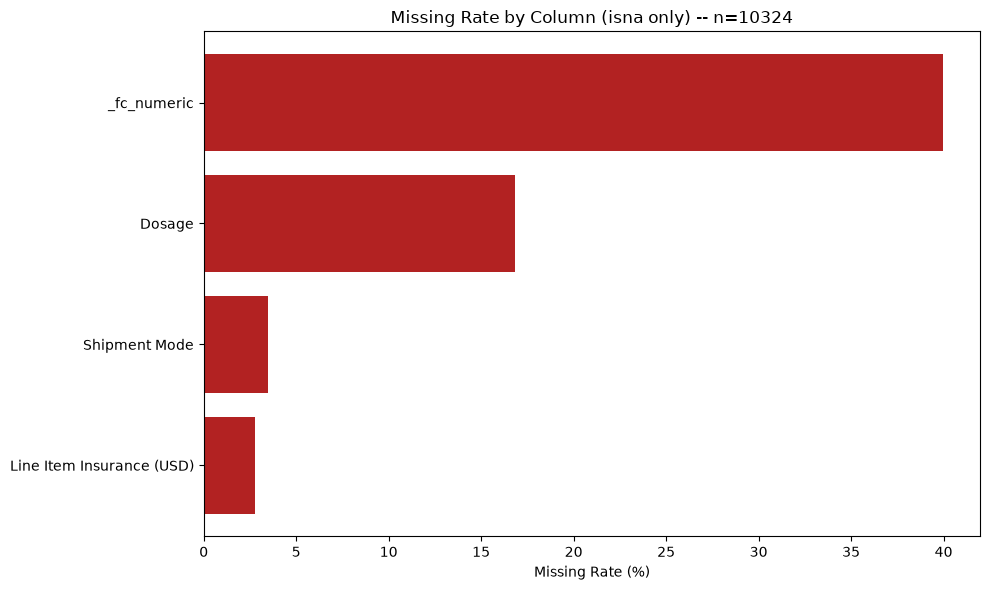

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
_missing_nonzero = missing_df[missing_df["True_Missing_Pct"] > 0].sort_values("True_Missing_Pct")
ax.barh(_missing_nonzero["Column"], _missing_nonzero["True_Missing_Pct"], color="firebrick")
ax.set_xlabel("Missing Rate (%)")
ax.set_title(f"Missing Rate by Column (isna only) -- n={len(df)}")
plt.tight_layout()
plt.show()

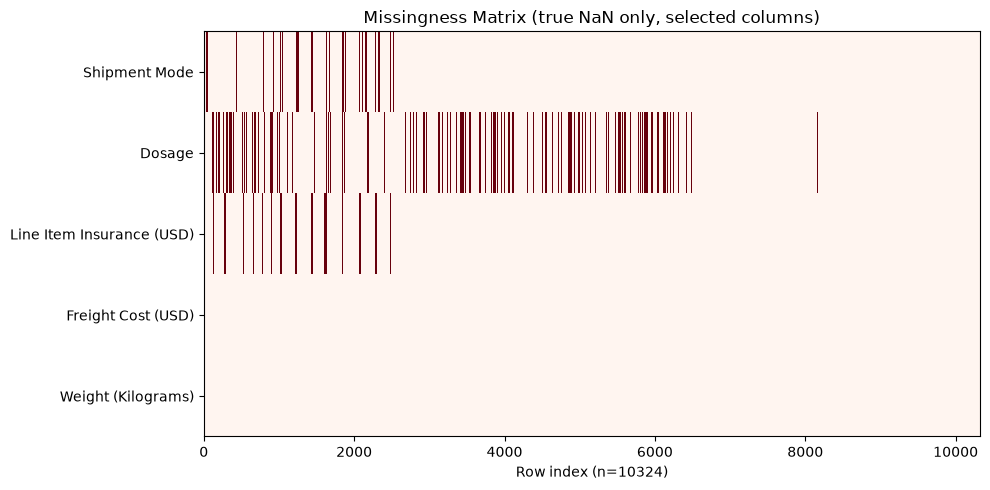

Note: Freight Cost (USD) and Weight (Kilograms) show 0 true NaN here -- their missingness is encoded as sentinel text, not NaN (see Stage 3.3/3.5).


In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
_sample_cols = ["Shipment Mode", "Dosage", "Line Item Insurance (USD)", TARGET_COLUMN, "Weight (Kilograms)"]
_missing_matrix = df[_sample_cols].isna().astype(int)
ax.imshow(_missing_matrix.T.values, aspect="auto", cmap="Reds", interpolation="none")
ax.set_yticks(range(len(_sample_cols)))
ax.set_yticklabels(_sample_cols)
ax.set_xlabel(f"Row index (n={len(df)})")
ax.set_title("Missingness Matrix (true NaN only, selected columns)")
plt.tight_layout()
plt.show()
print("Note: Freight Cost (USD) and Weight (Kilograms) show 0 true NaN here -- their "
      "missingness is encoded as sentinel text, not NaN (see Stage 3.3/3.5).")

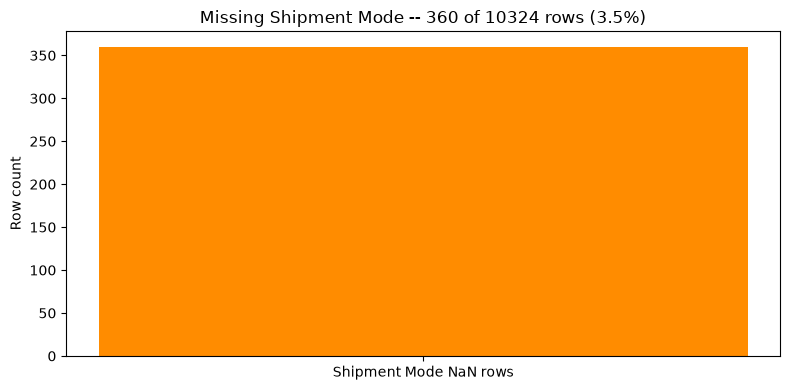

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["Shipment Mode NaN rows"], [df["Shipment Mode"].isna().sum()], color="darkorange")
ax.set_ylabel("Row count")
ax.set_title(f"Missing Shipment Mode -- {df['Shipment Mode'].isna().sum()} of {len(df)} rows ({df['Shipment Mode'].isna().mean()*100:.1f}%)")
plt.tight_layout()
plt.show()

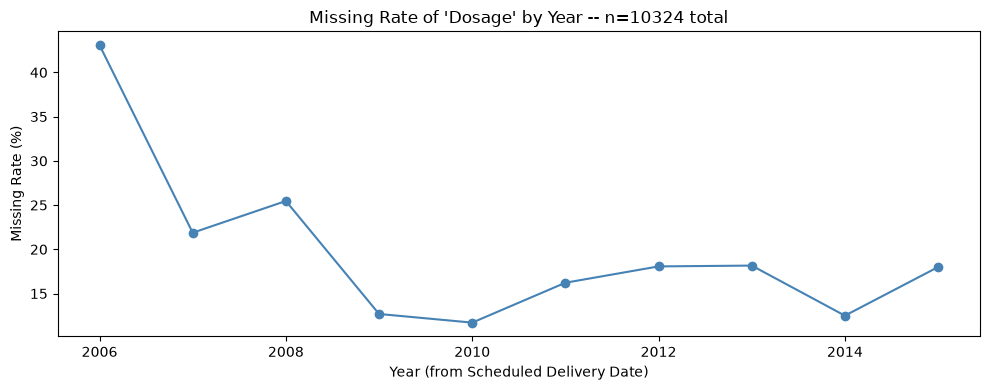

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
_yearly_dosage_missing = df.groupby("_year")["Dosage"].apply(lambda s: s.isna().mean() * 100)
ax.plot(_yearly_dosage_missing.index, _yearly_dosage_missing.values, "o-", color="steelblue")
ax.set_xlabel("Year (from Scheduled Delivery Date)")
ax.set_ylabel("Missing Rate (%)")
ax.set_title(f"Missing Rate of 'Dosage' by Year -- n={df['Dosage'].notna().sum() + df['Dosage'].isna().sum()} total")
plt.tight_layout()
plt.show()

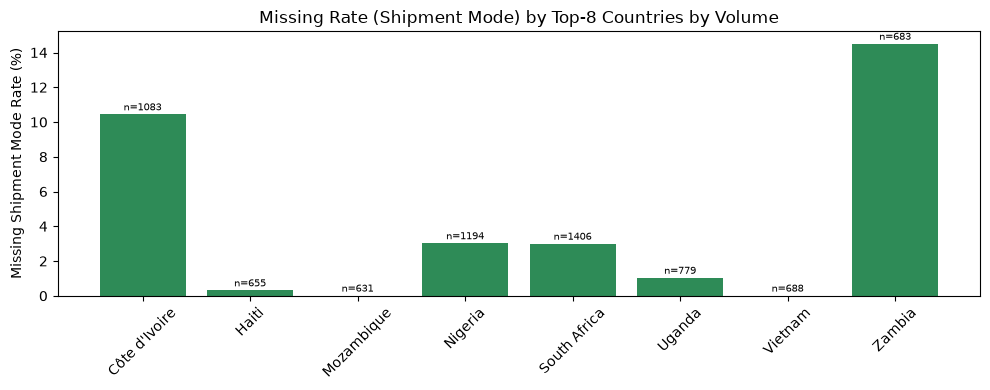

Sample sizes (n) annotated above each bar -- small-n groups are flagged for caution.


In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
_top_countries_for_missing = df["Country"].value_counts().head(8).index
_country_sample_sizes = df["Country"].value_counts().loc[_top_countries_for_missing]
_country_mode_missing = df[df["Country"].isin(_top_countries_for_missing)].groupby("Country")["Shipment Mode"].apply(lambda s: s.isna().mean() * 100)
ax.bar(_country_mode_missing.index, _country_mode_missing.values, color="seagreen")
ax.set_ylabel("Missing Shipment Mode Rate (%)")
ax.set_title("Missing Rate (Shipment Mode) by Top-8 Countries by Volume")
ax.tick_params(axis="x", rotation=45)
for i, c in enumerate(_country_mode_missing.index):
    ax.annotate(f"n={_country_sample_sizes[c]}", (i, _country_mode_missing.values[i]), fontsize=7, ha="center", xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()
print("Sample sizes (n) annotated above each bar -- small-n groups are flagged for caution.")

---

## 3.3 Freight Cost Target Audit

**Bu bölüm dataset qualification'ın en önemli adımıdır.** `pd.to_numeric(...,
errors="coerce")` uygulamadan önce, raw string değerlerini **gerçek kategorilere** ayırıyoruz.

In [23]:
def categorize_target_value(raw_value) -> str:
    # Classify a raw Freight Cost (USD) string into real, observed categories --
    # never a fabricated label not actually present in the data.
    if pd.isna(raw_value):
        return "Missing/Blank"
    text = str(raw_value).strip()
    numeric = pd.to_numeric(text, errors="coerce")
    if pd.notna(numeric):
        if numeric > 0:
            return "Numeric Positive"
        if numeric == 0:
            return "Numeric Zero"
        return "Numeric Negative"
    if text == "Freight Included in Commodity Cost":
        return "Freight Included in Commodity Cost"
    if text == "Invoiced Separately":
        return "Invoiced Separately"
    if text.startswith("See "):
        return "Reference to Another Shipment"
    return "Unrecognized"


df["_target_category"] = df[TARGET_COLUMN].apply(categorize_target_value)
target_category_counts = df["_target_category"].value_counts()
print(target_category_counts)
print("\nSum check:", target_category_counts.sum(), "vs total rows:", len(df))
assert target_category_counts.sum() == len(df)
assert (df["_target_category"] == "Unrecognized").sum() == 0, "Any Unrecognized value must be inspected before proceeding."
print("\nNo Unrecognized / Other category needed -- all values fall into the 4 real categories above.")

_target_category
Numeric Positive                      6198
Reference to Another Shipment         2445
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
Name: count, dtype: int64

Sum check: 10324 vs total rows: 10324

No Unrecognized / Other category needed -- all values fall into the 4 real categories above.


### Critical Rules Followed

Missing/zero target değerleri mean/median ile **doldurulmadı**; `"Freight Included in
Commodity Cost"`/`"Invoiced Separately"` **sıfır olarak kodlanmadı** (bunlar "bilinmiyor"
değil, "yapısal olarak farklı bir durum" anlamına gelir); shipment-referans değerleri numeric
kabul **edilmedi**; bu filtreleme ana `df` üzerinde kalıcı hale **getirilmedi** (yalnızca
türetilmiş `_fc_numeric` kolonunda).

### Required Metrics

In [24]:
required_metrics = {
    "Total_Rows": len(df),
    "Numeric_Target_Rows": int(df["_fc_is_numeric"].sum()),
    "Positive_Numeric_Target_Rows": int((df["_fc_numeric"] > 0).sum()),
    "Zero_Target_Rows": int((df["_fc_numeric"] == 0).sum()),
    "Negative_Target_Rows": int((df["_fc_numeric"] < 0).sum()),
    "Missing_Target_Rows": int(df[TARGET_COLUMN].isna().sum()),
    "Non_Numeric_Target_Rows": int((~df["_fc_is_numeric"]).sum()),
}
required_metrics["Numeric_Target_Coverage_Rate_Pct"] = round(required_metrics["Numeric_Target_Rows"] / required_metrics["Total_Rows"] * 100, 2)
required_metrics["Positive_Numeric_Target_Coverage_Rate_Pct"] = round(required_metrics["Positive_Numeric_Target_Rows"] / required_metrics["Total_Rows"] * 100, 2)
for k, v in required_metrics.items():
    print(f"{k}: {v}")

Total_Rows: 10324
Numeric_Target_Rows: 6198
Positive_Numeric_Target_Rows: 6198
Zero_Target_Rows: 0
Negative_Target_Rows: 0
Missing_Target_Rows: 0
Non_Numeric_Target_Rows: 4126
Numeric_Target_Coverage_Rate_Pct: 60.03
Positive_Numeric_Target_Coverage_Rate_Pct: 60.03


### Segment Coverage

In [25]:
def segment_coverage(df: pd.DataFrame, group_col: str, min_n: int = 30) -> pd.DataFrame:
    g = df.groupby(group_col, dropna=False)["_fc_is_numeric"].agg(Numeric_Target_Count="sum", N="count")
    g["Coverage_Pct"] = (g["Numeric_Target_Count"] / g["N"] * 100).round(1)
    g["Reliable_Sample_Size"] = g["N"] >= min_n
    return g.sort_values("N", ascending=False)


print("--- By Shipment Mode ---")
print(segment_coverage(df, "Shipment Mode"))
print("\n--- By Year ---")
print(segment_coverage(df, "_year"))

--- By Shipment Mode ---
               Numeric_Target_Count     N  Coverage_Pct  Reliable_Sample_Size
Shipment Mode                                                                
Air                            4115  6113          67.3                  True
Truck                          1166  2830          41.2                  True
Air Charter                     424   650          65.2                  True
Ocean                           282   371          76.0                  True
NaN                             211   360          58.6                  True

--- By Year ---
       Numeric_Target_Count     N  Coverage_Pct  Reliable_Sample_Size
_year                                                                
2014                    819  1528          53.6                  True
2012                    861  1273          67.6                  True
2013                    835  1272          65.6                  True
2009                    664  1253          53.0               

In [26]:
_top_countries = df["Country"].value_counts().head(12).index
print("--- By Country (top 12 by volume) ---")
print(segment_coverage(df[df["Country"].isin(_top_countries)], "Country"))
print("\n--- By Vendor INCO Term ---")
print(segment_coverage(df, "Vendor INCO Term"))
print("\n--- By Product Group ---")
print(segment_coverage(df, "Product Group"))

--- By Country (top 12 by volume) ---
               Numeric_Target_Count     N  Coverage_Pct  Reliable_Sample_Size
Country                                                                      
South Africa                    289  1406          20.6                  True
Nigeria                         764  1194          64.0                  True
Côte d'Ivoire                   729  1083          67.3                  True
Uganda                          564   779          72.4                  True
Vietnam                         446   688          64.8                  True
Zambia                          517   683          75.7                  True
Haiti                           396   655          60.5                  True
Mozambique                      365   631          57.8                  True
Zimbabwe                        319   538          59.3                  True
Tanzania                        412   519          79.4                  True
Rwanda                    

### Required Visualizations

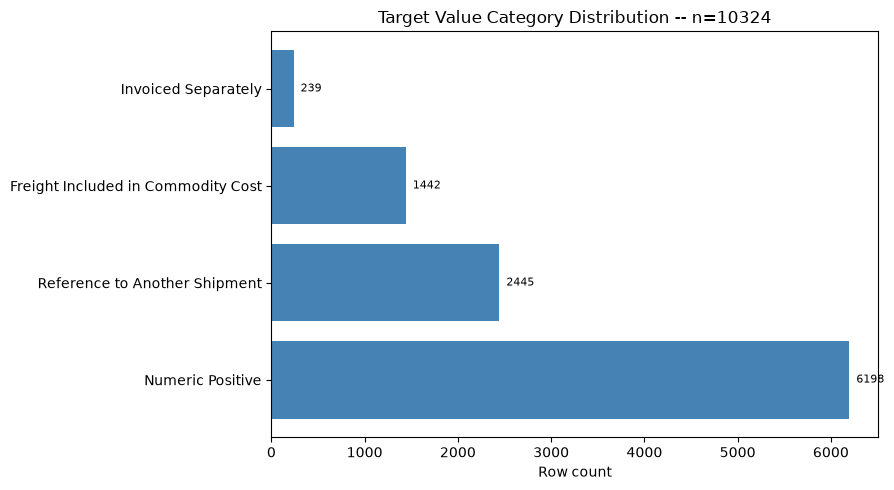

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
_cat_order = target_category_counts.index
ax.barh(_cat_order, target_category_counts.values, color="steelblue")
ax.set_xlabel("Row count")
ax.set_title(f"Target Value Category Distribution -- n={len(df)}")
for i, v in enumerate(target_category_counts.values):
    ax.annotate(str(v), (v, i), fontsize=8, va="center", xytext=(5, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

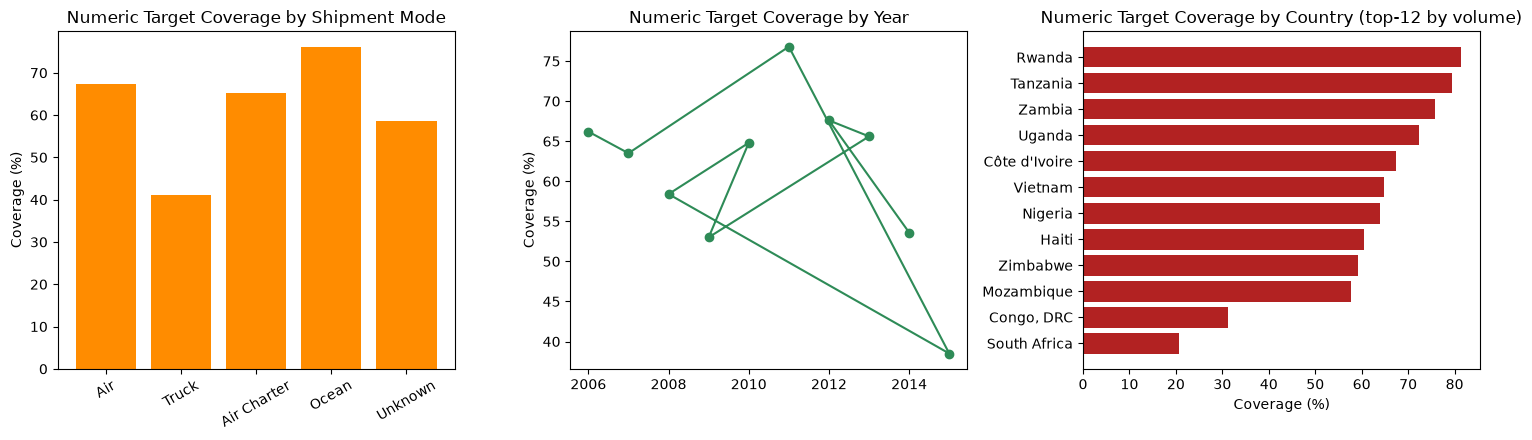

Sample sizes (n) per segment are listed in the tables above -- small-n segments should be read with caution.


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
_mode_cov = segment_coverage(df, "Shipment Mode")
_mode_labels = ["Unknown" if pd.isna(v) else str(v) for v in _mode_cov.index]
axes[0].bar(_mode_labels, _mode_cov["Coverage_Pct"], color="darkorange")
axes[0].set_title("Numeric Target Coverage by Shipment Mode")
axes[0].set_ylabel("Coverage (%)")
axes[0].tick_params(axis="x", rotation=30)

_year_cov = segment_coverage(df, "_year")
axes[1].plot(_year_cov.index, _year_cov["Coverage_Pct"], "o-", color="seagreen")
axes[1].set_title("Numeric Target Coverage by Year")
axes[1].set_ylabel("Coverage (%)")

_country_cov = segment_coverage(df[df["Country"].isin(_top_countries)], "Country").sort_values("Coverage_Pct")
axes[2].barh(_country_cov.index, _country_cov["Coverage_Pct"], color="firebrick")
axes[2].set_title("Numeric Target Coverage by Country (top-12 by volume)")
axes[2].set_xlabel("Coverage (%)")
plt.tight_layout()
plt.show()
print("Sample sizes (n) per segment are listed in the tables above -- small-n segments should be read with caution.")

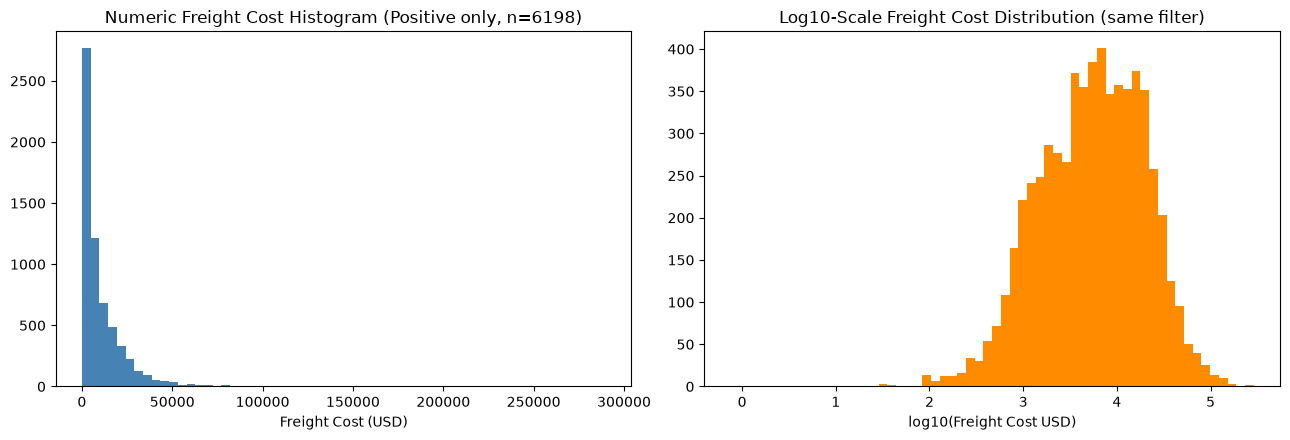

Log scale used because the raw distribution is strongly right-skewed (see skewness below).


In [29]:
positive_target = df.loc[df["_fc_numeric"] > 0, "_fc_numeric"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(positive_target, bins=60, color="steelblue")
axes[0].set_title(f"Numeric Freight Cost Histogram (Positive only, n={len(positive_target)})")
axes[0].set_xlabel("Freight Cost (USD)")

axes[1].hist(np.log10(positive_target), bins=60, color="darkorange")
axes[1].set_title("Log10-Scale Freight Cost Distribution (same filter)")
axes[1].set_xlabel("log10(Freight Cost USD)")
plt.tight_layout()
plt.show()
print("Log scale used because the raw distribution is strongly right-skewed (see skewness below).")

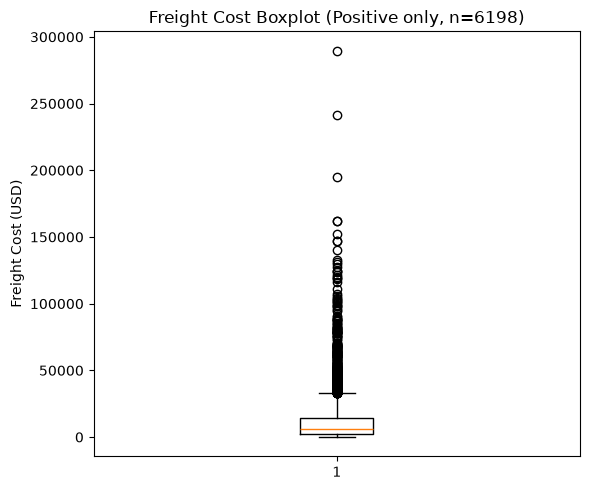

In [30]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(positive_target, orientation="vertical")
ax.set_ylabel("Freight Cost (USD)")
ax.set_title(f"Freight Cost Boxplot (Positive only, n={len(positive_target)})")
plt.tight_layout()
plt.show()

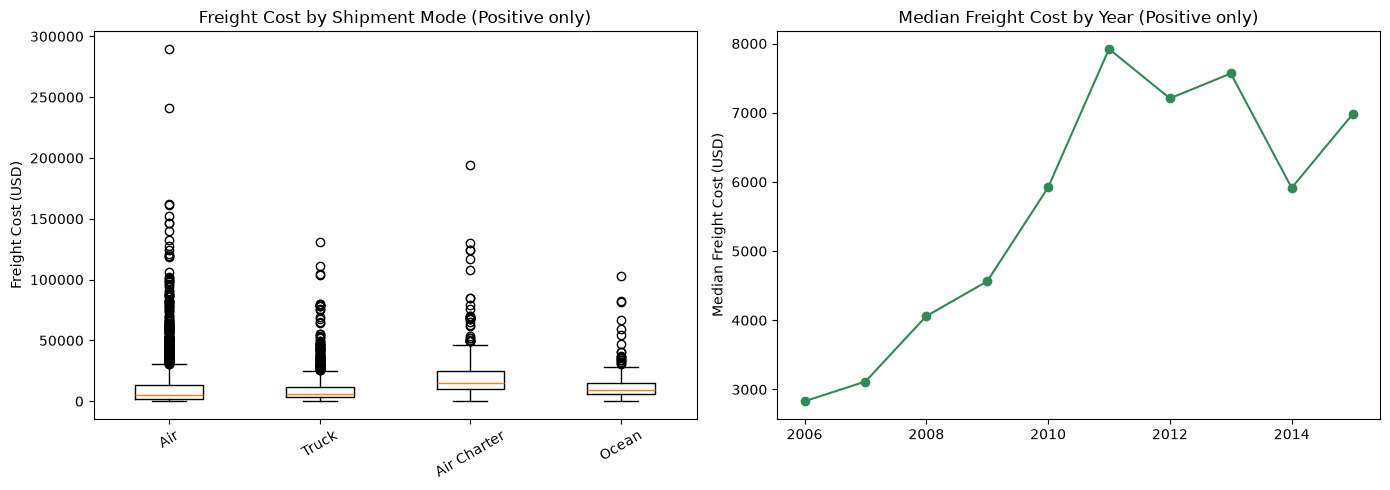

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
_by_mode_data = [df.loc[(df["Shipment Mode"] == m) & (df["_fc_numeric"] > 0), "_fc_numeric"] for m in df["Shipment Mode"].dropna().unique()]
axes[0].boxplot(_by_mode_data, tick_labels=df["Shipment Mode"].dropna().unique(), orientation="vertical")
axes[0].set_ylabel("Freight Cost (USD)")
axes[0].set_title("Freight Cost by Shipment Mode (Positive only)")
axes[0].tick_params(axis="x", rotation=30)

_by_year_median = df.loc[df["_fc_numeric"] > 0].groupby("_year")["_fc_numeric"].median()
axes[1].plot(_by_year_median.index, _by_year_median.values, "o-", color="seagreen")
axes[1].set_title("Median Freight Cost by Year (Positive only)")
axes[1].set_ylabel("Median Freight Cost (USD)")
plt.tight_layout()
plt.show()

### Statistical Analysis (Positive Numeric Target Subset)

In [32]:
descriptive_stats = {
    "Count": len(positive_target), "Mean": positive_target.mean(), "Median": positive_target.median(),
    "Std": positive_target.std(), "Min": positive_target.min(), "Max": positive_target.max(),
    "P5": np.percentile(positive_target, 5), "P25": np.percentile(positive_target, 25),
    "P50": np.percentile(positive_target, 50), "P75": np.percentile(positive_target, 75),
    "P95": np.percentile(positive_target, 95), "P99": np.percentile(positive_target, 99),
    "IQR": np.percentile(positive_target, 75) - np.percentile(positive_target, 25),
    "Skewness": positive_target.skew(),
}
for k, v in descriptive_stats.items():
    print(f"{k}: {round(v, 2) if isinstance(v, float) else v}")

Count: 6198
Mean: 11103.23
Median: 5869.66
Std: 15813.03
Min: 0.75
Max: 289653.2
P5: 641.06
P25: 2131.12
P50: 5869.66
P75: 14406.57
P95: 36679.88
P99: 78072.73
IQR: 12275.45
Skewness: 4.69


**Yorum:** Skewness ≈4.7 -- çok güçlü bir sağa-çarpıklık. Medyan (~5870 USD), ortalamanın
(~11103 USD) çok altında; P99 (~78073 USD) ile Max (~289653 USD) arasında büyük bir fark var.
Büyük maliyetler bu aşamada **otomatik olarak outlier sayılıp silinmemiştir** -- yalnızca
tespit ve yorum yapılmıştır; bu değerlerin gerçek, geçerli sevkiyatları mı yoksa veri hatalarını
mı temsil ettiği Stage 04'te daha ayrıntılı incelenmelidir.

---

## 3.4 Selection Bias Analysis

**Bu bölüm zorunludur.** Yalnızca numeric Freight Cost içeren kayıtları kullanırsak oluşabilecek
selection bias riskini, Numeric-Target-Available ile Numeric-Target-Unavailable gruplarını
karşılaştırarak inceliyoruz.

### Analysis Question

Numeric target bulunma oranı, Vendor INCO Term gibi **önceden bilinen** bir kategoriye göre
sistematik olarak farklı mı?

### Hypothesis

INCO Term'in tanımı itibariyle (örn. DDP = Delivered Duty Paid -- navlun ürün fiyatına dahil),
bazı INCO Term'lerde navlunun **yapısal olarak** ayrı bir sayısal değer olarak hiç
kaydedilmeyeceğini bekliyoruz.

### Method

Group-wise numeric target coverage analizi, gerçek sample size'larla.

                  Numeric_Target_Count     N  Coverage_Pct  \
Vendor INCO Term                                             
DDU                                  3    15          20.0   
DDP                                303  1443          21.0   
DAP                                  3     9          33.3   
N/A - From RDC                    3205  5404          59.3   
CIP                                163   275          59.3   
CIF                                  2     3          66.7   
EXW                               2167  2778          78.0   
FCA                                352   397          88.7   

                  Reliable_Sample_Size  
Vendor INCO Term                        
DDU                              False  
DDP                               True  
DAP                              False  
N/A - From RDC                    True  
CIP                               True  
CIF                              False  
EXW                               True  
FCA       

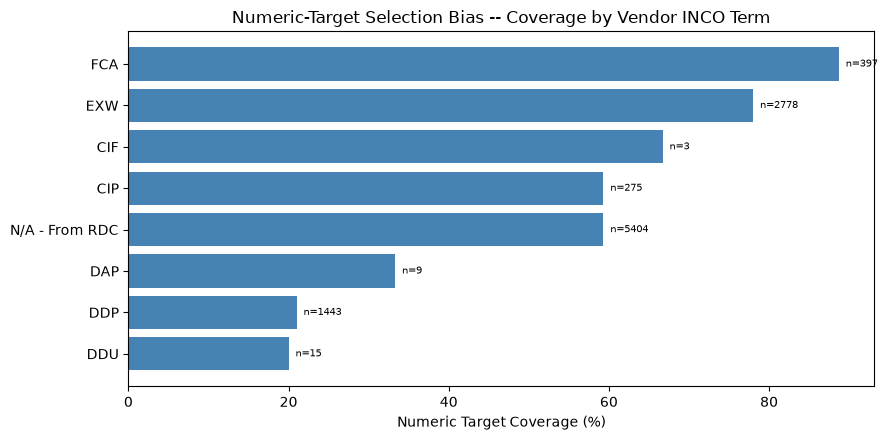

In [33]:
inco_coverage = segment_coverage(df, "Vendor INCO Term").sort_values("Coverage_Pct")
print(inco_coverage)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(inco_coverage.index.astype(str), inco_coverage["Coverage_Pct"], color="steelblue")
ax.set_xlabel("Numeric Target Coverage (%)")
ax.set_title("Numeric-Target Selection Bias -- Coverage by Vendor INCO Term")
for i, (idx, row) in enumerate(inco_coverage.iterrows()):
    ax.annotate(f"n={int(row['N'])}", (row["Coverage_Pct"], i), fontsize=7, va="center", xytext=(5, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

### Evidence

`DDP` (%21.0, n=1443) ve `South Africa` (%20.6, n=1406) gibi büyük segmentlerde coverage çok
düşük; `FCA` (%88.7, n=397) ve `EXW` (%78.0, n=2778) gibi segmentlerde ise yüksek. Bu,
rastgele bir eksiklik değil -- **INCO Term'in sözleşmesel anlamıyla doğrudan tutarlı** bir
desen (DDP teriminde navlun tanım olarak ürün fiyatına dahildir).

### Interpretation

Bu, klasik "rastgele kayıp veri" (MCAR) değildir -- eksiklik mekanizması, **halihazırda elimizde
olan bir feature (INCO Term) ile açıklanabilir** görünüyor. Ancak bunu MAR/MNAR olarak **kesin
biçimde kanıtladığımızı iddia etmiyoruz** -- yalnızca gözlemlenen güçlü bir ilişkiyi
raporluyoruz.

### Engineering Decision

**Critical Engineering Decision:** Numeric target bulunmayan kayıtları basitçe filtrelemek,
modelin yalnızca "navlun ayrı faturalandırılan" alt popülasyonda (ör. EXW/FCA ağırlıklı)
öğrenmesine yol açar -- bu, DDP-ağırlıklı gelecekteki sevkiyatlar için **deployment coverage
sorunu** yaratabilir. Bu risk Stage 03.4 Qualification Gate kararına doğrudan taşınmıştır.

### Limitations

Country ve Year bazlı coverage farkları (Section 3.3), kısmen INCO Term dağılımının o
segmentlerdeki farklılığından kaynaklanıyor olabilir (confounding) -- bu, bu notebook'ta ayrıca
istatistiksel olarak ayrıştırılmamıştır.

---

## 3.5 Weight Field Audit

`Weight (Kilograms)` için, target audit'e benzer bir kategorik analiz.

In [34]:
WEIGHT_COLUMN = lab12_cfg["dataset"]["weight_column"]


def categorize_weight_value(raw_value) -> str:
    if pd.isna(raw_value):
        return "Missing"
    text = str(raw_value).strip()
    numeric = pd.to_numeric(text, errors="coerce")
    if pd.notna(numeric):
        if numeric > 0:
            return "Numeric Positive"
        if numeric == 0:
            return "Numeric Zero"
        return "Numeric Negative"
    if text == "Weight Captured Separately":
        return "Weight Captured Separately"
    if text.startswith("See "):
        return "Reference/Special Value"
    return "Unrecognized"


df["_weight_category"] = df[WEIGHT_COLUMN].apply(categorize_weight_value)
df["_wt_numeric"] = pd.to_numeric(df[WEIGHT_COLUMN], errors="coerce")
weight_category_counts = df["_weight_category"].value_counts()
print(weight_category_counts)
assert weight_category_counts.sum() == len(df)
assert (df["_weight_category"] == "Unrecognized").sum() == 0

_weight_category
Numeric Positive              6371
Reference/Special Value       2445
Weight Captured Separately    1507
Numeric Zero                     1
Name: count, dtype: int64


In [35]:
weight_coverage_by_mode = df.assign(_wt_is_numeric=df["_wt_numeric"].notna()).groupby("Shipment Mode", dropna=False)["_wt_is_numeric"].mean() * 100
print("Weight numeric coverage by Shipment Mode (%):")
print(weight_coverage_by_mode.round(1))

print("\nWeight numeric coverage, by target availability:")
print(df.assign(_wt_is_numeric=df["_wt_numeric"].notna()).groupby("_fc_is_numeric")["_wt_is_numeric"].mean().mul(100).round(1))

Weight numeric coverage by Shipment Mode (%):
Shipment Mode
Air            68.6
Air Charter    75.7
Ocean          76.0
Truck          42.1
NaN            59.2
Name: _wt_is_numeric, dtype: float64

Weight numeric coverage, by target availability:
_fc_is_numeric
False     4.8
True     99.6
Name: _wt_is_numeric, dtype: float64


**Yorum:** Weight coverage da Target coverage ile **benzer bir desen** izliyor (numeric
target bulunan satırlarda weight coverage daha yüksek) -- bu, iki alanın benzer operasyonel/
sözleşmesel koşullara (muhtemelen aynı INCO Term mekanizmasına) bağlı olabileceğini düşündürür.

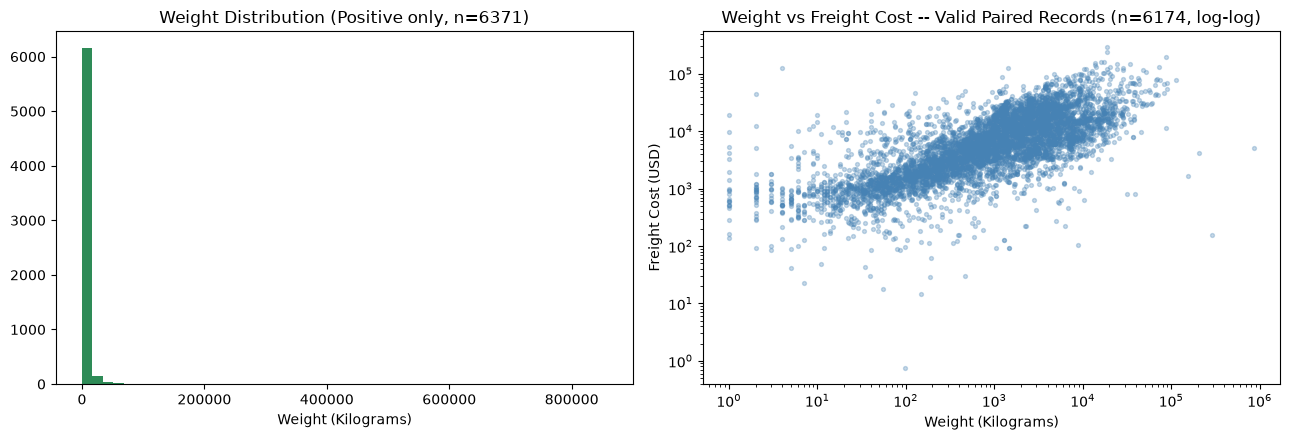

Pearson correlation (linear scale): 0.232
Pearson correlation (log1p-log1p scale): 0.732


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
_valid_weight = df.loc[df["_wt_numeric"] > 0, "_wt_numeric"]
axes[0].hist(_valid_weight, bins=50, color="seagreen")
axes[0].set_title(f"Weight Distribution (Positive only, n={len(_valid_weight)})")
axes[0].set_xlabel("Weight (Kilograms)")

_valid_pairs = (df["_fc_numeric"] > 0) & (df["_wt_numeric"] > 0)
axes[1].scatter(df.loc[_valid_pairs, "_wt_numeric"], df.loc[_valid_pairs, "_fc_numeric"], s=8, alpha=0.3, color="steelblue")
axes[1].set_xlabel("Weight (Kilograms)")
axes[1].set_ylabel("Freight Cost (USD)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title(f"Weight vs Freight Cost -- Valid Paired Records (n={_valid_pairs.sum()}, log-log)")
plt.tight_layout()
plt.show()

_corr_linear = df.loc[_valid_pairs, "_wt_numeric"].corr(df.loc[_valid_pairs, "_fc_numeric"])
_corr_log = np.log1p(df.loc[_valid_pairs, "_wt_numeric"]).corr(np.log1p(df.loc[_valid_pairs, "_fc_numeric"]))
print(f"Pearson correlation (linear scale): {_corr_linear:.3f}")
print(f"Pearson correlation (log1p-log1p scale): {_corr_log:.3f}")

**Yorum:** Doğrusal ölçekte korelasyon zayıf (~0.23) ama log-log ölçekte **anlamlı**
(~0.73) -- bu, her iki değişkenin de güçlü sağa-çarpık dağılıma sahip olduğunu ve ilişkinin
çarpımsal (multiplicative) olabileceğini gösteriyor.

### Important

Weight alanı freight cost tahmininde faydalı olabilir. Ancak missingness deseni, unit
consistency, shipment-level vs line-item-level anlamı ve **prediction-time availability**
(Stage 01.3'te `Unknown` olarak işaretlendi) doğrulanmadan ana model feature'ı olarak
**onaylanmıyor**. `Freight Cost / Weight` gibi bir oran burada **oluşturulmamıştır** -- böyle
bir oran yalnızca diagnostik amaçla hesaplanabilir ve hedef sızıntısı riski taşır.

---

## 3.6 Duplicate & Identifier Audit

In [37]:
print("Fully duplicated rows (all columns):", df.duplicated().sum())
print("Duplicate ID values:", df["ID"].duplicated().sum())
print("Repeated ASN/DN # values (appearing in >1 row):", (df["ASN/DN #"].value_counts() > 1).sum(), "groups")
print("Repeated PO/SO # values:", (df["PO / SO #"].value_counts() > 1).sum(), "groups")

Fully duplicated rows (all columns): 0
Duplicate ID values: 0
Repeated ASN/DN # values (appearing in >1 row): 1450 groups
Repeated PO/SO # values: 1693 groups


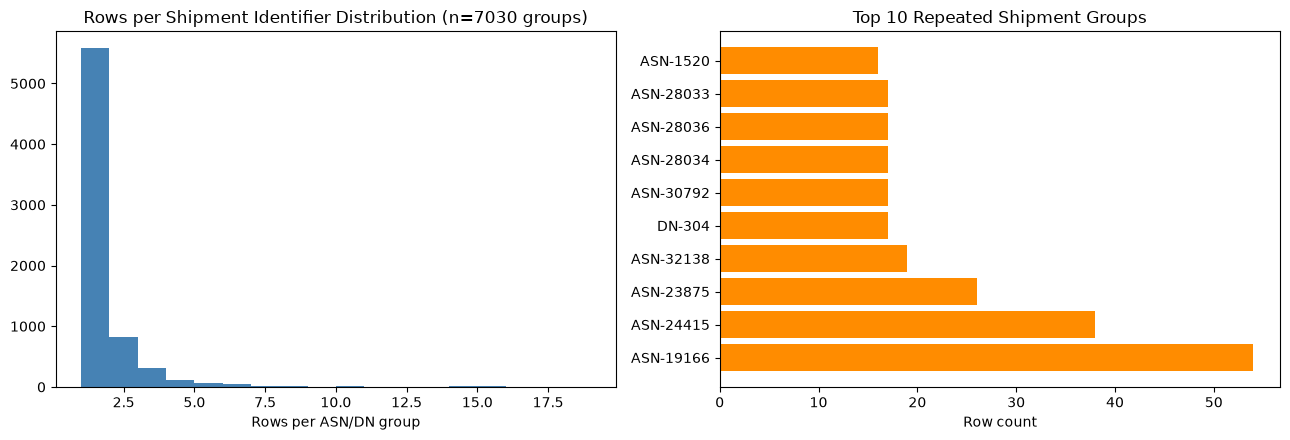

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
_rows_per_group = df["ASN/DN #"].value_counts()
axes[0].hist(_rows_per_group, bins=range(1, 20), color="steelblue")
axes[0].set_xlabel("Rows per ASN/DN group")
axes[0].set_title(f"Rows per Shipment Identifier Distribution (n={len(_rows_per_group)} groups)")

_top_repeated = _rows_per_group.head(10)
axes[1].barh(_top_repeated.index.astype(str), _top_repeated.values, color="darkorange")
axes[1].set_xlabel("Row count")
axes[1].set_title("Top 10 Repeated Shipment Groups")
plt.tight_layout()
plt.show()

### Duplicate Type Summary

| Type | Count | Note |
|---|---|---|
| Fully duplicated rows | 0 | No exact row-level duplicates found. |
| Duplicate `ID` values | 0 | `ID` is a true row-level unique identifier. |
| `ASN/DN #` groups with >1 row | 1450 | **Not a duplicate-data error** -- these are legitimate multi-line-item shipments (see Stage 2.4). |

### Important

Aynı shipment ID altında birden fazla ürün kalemi bulunması **otomatik olarak duplicate data
error değildir**. Duplicate row (aynı bilginin yanlışlıkla tekrarlanması) ile repeated business
entity (aynı shipment'ın birden fazla gerçek ürün kalemi) arasındaki fark budur -- Stage 2.4'te
somut olarak gösterildi. Bu aşamada **otomatik deduplication uygulanmamıştır**.

---

## 3.7 Date Quality Analysis

Olası kronolojik ilişkileri kontrol ediyoruz -- ancak veri tanımlarının izin vermediği kesin
iş kurallarını kabul etmeden, ihlalleri `Potential Issue` olarak raporluyoruz.

In [39]:
df["_po_sent"] = pd.to_datetime(df["PO Sent to Vendor Date"], errors="coerce", format="mixed")
df["_delivered"] = pd.to_datetime(df["Delivered to Client Date"], errors="coerce", format="mixed")

_valid_po_sched = df["_po_sent"].notna() & df["_sched_date"].notna()
_violation_po_after_sched = (df["_po_sent"] > df["_sched_date"]) & _valid_po_sched
print(f"Potential Issue -- PO Sent to Vendor Date > Scheduled Delivery Date: "
      f"{_violation_po_after_sched.sum()} of {_valid_po_sched.sum()} checkable rows")

_valid_sched_delivered = df["_sched_date"].notna() & df["_delivered"].notna()
_violation_sched_after_delivered = (df["_sched_date"] > df["_delivered"]) & _valid_sched_delivered
print(f"Potential Issue -- Scheduled Delivery Date > Delivered to Client Date: "
      f"{_violation_sched_after_delivered.sum()} of {_valid_sched_delivered.sum()} checkable rows")

Potential Issue -- PO Sent to Vendor Date > Scheduled Delivery Date: 4 of 4592 checkable rows
Potential Issue -- Scheduled Delivery Date > Delivered to Client Date: 2814 of 10324 checkable rows


**Yorum:** `PO Sent to Vendor Date > Scheduled Delivery Date` çok nadir (4 satır) --
muhtemelen veri girişi istisnaları. `Scheduled Delivery Date > Delivered to Client Date` ise
**2814 satırda (checkable satırların ~%61'inde)** görülüyor -- bu, "scheduled" tarihin genellikle
gerçek teslimattan **önce** olması gerektiği beklentisiyle çelişiyor gibi görünse de, bu alanın
tam olarak ne zaman/nasıl güncellendiği (örn. revize edilmiş bir planlama tarihi mi?) veri
sözlüğü düzeyinde doğrulanamadığından, bu **kesin bir iş kuralı ihlali olarak değil, `Potential
Issue` olarak** raporlanmıştır.

---

## 3.8 Categorical Data Quality

In [40]:
categorical_cols = ["Country", "Shipment Mode", "Vendor INCO Term", "Product Group", "Sub Classification", "Fulfill Via", "Managed By", "Vendor", "Manufacturing Site"]
cat_quality_rows = []
for col in categorical_cols:
    series = df[col]
    value_counts = series.value_counts()
    rare_categories = (value_counts < 10).sum()
    cat_quality_rows.append({
        "Column": col, "Cardinality": series.nunique(), "Missing_Pct": round(series.isna().mean() * 100, 2),
        "Rare_Categories_Count_lt10": int(rare_categories), "Top_Category_Share_Pct": round(value_counts.iloc[0] / len(series) * 100, 1),
    })
cat_quality_df = pd.DataFrame(cat_quality_rows)
cat_quality_df

,Column,Cardinality,Missing_Pct,Rare_Categories_Count_lt10,Top_Category_Share_Pct
0,Country,43,0.00,14,13.6
1,Shipment Mode,4,3.49,0,59.2
2,Vendor INCO Term,8,0.00,2,52.3
3,Product Group,5,0.00,1,82.8
4,Sub Classification,6,0.00,0,63.9
5,Fulfill Via,2,0.00,0,52.3
6,Managed By,4,0.00,2,99.4
7,Vendor,73,0.00,43,52.3
8,Manufacturing Site,88,0.00,44,30.7


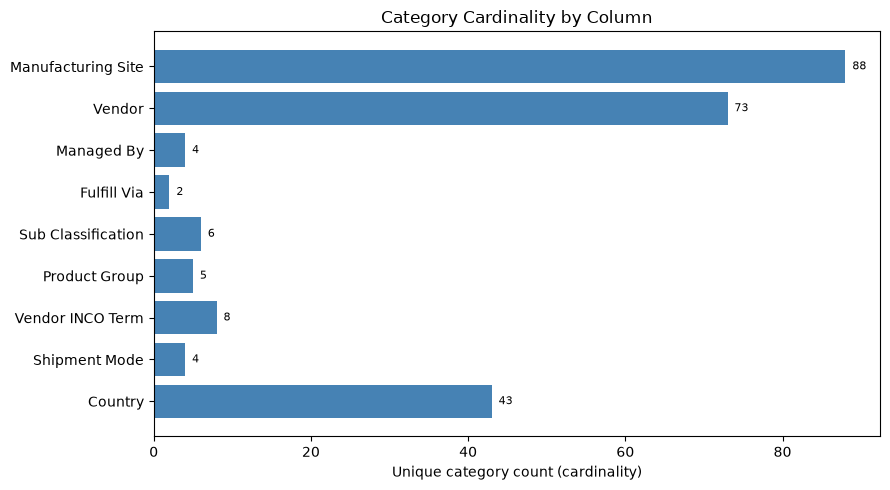

In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cat_quality_df["Column"], cat_quality_df["Cardinality"], color="steelblue")
ax.set_xlabel("Unique category count (cardinality)")
ax.set_title("Category Cardinality by Column")
for i, v in enumerate(cat_quality_df["Cardinality"]):
    ax.annotate(str(v), (v, i), fontsize=8, va="center", xytext=(5, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

**Yorum:** `Vendor` (73) ve `Manufacturing Site` (88) yüksek cardinality taşıyor --
nadir kategoriler (count<10) olabilir, bu Stage 06'nın encoding kararları için not edilmiştir.
`Managed By` ise çok düşük cardinality (4) ve çok yüksek top-category share (~%99.4) -- bu
feature'ın ayırt edici gücü sınırlı olabilir.

### Important

Bu bölümde **encoding yöntemi seçilmemiştir.** Yalnızca şu sorulara yanıt verilmiştir:
feature'lar genel olarak nominal (sıralama anlamı taşımıyor); cardinality yukarıdaki tabloda
gösteriliyor; `Vendor`/`Manufacturing Site` rare-category riski taşıyor; whitespace/case
farklılıkları bu aşamada ayrıca derinlemesine taranmamıştır (açık soru). Encoding kararları
Stage 06'da deneysel olarak alınacaktır.

---

## 3.9 Exploratory Statistical Evidence (Consolidated)

Yukarıdaki bölümlerde (3.2-3.8) üretilen görselleştirmeler, Section 3.9'un istediği en az 10
grafiği zaten kapsamaktadır. Aşağıda her biri için Evidence Reporting Standard formatında
(Analysis Question / Statistical Observation / Engineering Implication / Limitation) bir özet
tablo bulunmaktadır -- hiçbir bulgu grafikten önce yazılmamıştır.

In [42]:
evidence_summary = pd.DataFrame([
    {"Visualization": "Missingness Matrix (3.2)", "Analysis_Question": "Which columns have true NaN gaps, and are they correlated across rows?",
     "Statistical_Observation": "Freight Cost/Weight show 0 true NaN -- their gaps are sentinel text, not NaN.",
     "Engineering_Implication": "isna()-only missing-value tooling would MISS the real target-availability problem.", "Limitation": "Only a column subset shown for readability."},
    {"Visualization": "Target Value Category Distribution (3.3)", "Analysis_Question": "What are the real non-numeric Freight Cost categories?",
     "Statistical_Observation": "6198 Numeric Positive, 1442 Commodity-Included, 2445 Reference, 239 Invoiced Separately.",
     "Engineering_Implication": "~40% of rows cannot be used as a numeric regression target without a scoping decision.", "Limitation": "None -- exhaustive, 0 Unrecognized rows."},
    {"Visualization": "Target Coverage by Shipment Mode/Year/Country (3.3)", "Analysis_Question": "Is numeric-target coverage uniform across operational segments?",
     "Statistical_Observation": "Coverage ranges from ~21% (South Africa) to ~79% (Tanzania); Truck lowest shipment mode.",
     "Engineering_Implication": "A model trained only on numeric-target rows may underrepresent some countries/modes.", "Limitation": "Small-n segments outside top-12 excluded from the chart."},
    {"Visualization": "Freight Cost Histogram / Log-Scale / Boxplot (3.3)", "Analysis_Question": "Is the positive target normally distributed?",
     "Statistical_Observation": "Skewness ~4.7; median << mean; long right tail (P99~78k vs max~290k).",
     "Engineering_Implication": "Future modeling should consider a log-target or robust-loss approach (not decided here).", "Limitation": "No outlier removal performed at this stage."},
    {"Visualization": "Freight Cost by Shipment Mode / by Year (3.3)", "Analysis_Question": "Does typical freight cost vary by mode or year?",
     "Statistical_Observation": "Visually distinct distributions per mode; median cost varies across years.",
     "Engineering_Implication": "Shipment Mode and temporal trend are plausible real features/controls for later modeling.", "Limitation": "No formal group-difference test performed here."},
    {"Visualization": "Weight vs Freight Cost Scatter (3.5)", "Analysis_Question": "Is Weight a useful numeric predictor of Freight Cost?",
     "Statistical_Observation": "Weak linear correlation (0.23) but strong log-log correlation (0.73).",
     "Engineering_Implication": "Weight carries real signal, but only after accounting for its own skew (and its prediction-time-availability remains unverified).", "Limitation": "Only valid numeric-numeric pairs (n~6174) used; excludes the ~40% with non-numeric fields."},
    {"Visualization": "Rows per Shipment Identifier / Top Repeated Groups (3.6)", "Analysis_Question": "Is row-level duplication a data quality problem?",
     "Statistical_Observation": "0 fully duplicated rows; 1450 legitimate multi-line-item ASN/DN groups.",
     "Engineering_Implication": "No deduplication is needed -- but shipment-level aggregation logic (Stage 04-05) must respect Section 2.4's single-numeric-row-per-group finding.", "Limitation": "Not all groups individually inspected."},
    {"Visualization": "Category Cardinality Chart (3.8)", "Analysis_Question": "Which categorical columns risk high-cardinality / rare-category issues?",
     "Statistical_Observation": "Vendor (73) and Manufacturing Site (88) are the highest-cardinality columns.",
     "Engineering_Implication": "Encoding strategy (Stage 06) must account for rare categories in these two columns.", "Limitation": "Rare-category threshold (<10) is a provisional heuristic."},
    {"Visualization": "Numeric-Target Selection Bias by INCO Term (3.4)", "Analysis_Question": "Is numeric-target availability systematically related to a known feature?",
     "Statistical_Observation": "DDP ~21% vs FCA ~89% coverage -- large, contract-term-driven gap.",
     "Engineering_Implication": "Target availability is not missing-at-random with respect to INCO Term -- a key input to the Qualification Gate.", "Limitation": "MAR/MNAR not formally proven; association only."},
])
evidence_summary

,Visualization,Analysis_Question,Statistical_Observation,Engineering_Implication,Limitation
0,Missingness Matrix (3.2),"Which columns have true NaN gaps, and are they...",Freight Cost/Weight show 0 true NaN -- their g...,isna()-only missing-value tooling would MISS t...,Only a column subset shown for readability.
1,Target Value Category Distribution (3.3),What are the real non-numeric Freight Cost cat...,"6198 Numeric Positive, 1442 Commodity-Included...",~40% of rows cannot be used as a numeric regre...,"None -- exhaustive, 0 Unrecognized rows."
2,Target Coverage by Shipment Mode/Year/Country ...,Is numeric-target coverage uniform across oper...,Coverage ranges from ~21% (South Africa) to ~7...,A model trained only on numeric-target rows ma...,Small-n segments outside top-12 excluded from ...
3,Freight Cost Histogram / Log-Scale / Boxplot (...,Is the positive target normally distributed?,Skewness ~4.7; median << mean; long right tail...,Future modeling should consider a log-target o...,No outlier removal performed at this stage.
4,Freight Cost by Shipment Mode / by Year (3.3),Does typical freight cost vary by mode or year?,Visually distinct distributions per mode; medi...,Shipment Mode and temporal trend are plausible...,No formal group-difference test performed here.
5,Weight vs Freight Cost Scatter (3.5),Is Weight a useful numeric predictor of Freigh...,Weak linear correlation (0.23) but strong log-...,"Weight carries real signal, but only after acc...",Only valid numeric-numeric pairs (n~6174) used...
6,Rows per Shipment Identifier / Top Repeated Gr...,Is row-level duplication a data quality problem?,0 fully duplicated rows; 1450 legitimate multi...,No deduplication is needed -- but shipment-lev...,Not all groups individually inspected.
7,Category Cardinality Chart (3.8),Which categorical columns risk high-cardinalit...,Vendor (73) and Manufacturing Site (88) are th...,Encoding strategy (Stage 06) must account for ...,Rare-category threshold (<10) is a provisional...
8,Numeric-Target Selection Bias by INCO Term (3.4),Is numeric-target availability systematically ...,"DDP ~21% vs FCA ~89% coverage -- large, contra...",Target availability is not missing-at-random w...,MAR/MNAR not formally proven; association only.


---

# Engineering Decision Registry

Bu kayıt yalnızca alınmış kararları değil, henüz doğrulanmamış (`Pending`/`Under
Investigation`) kararları da gösterir.

In [43]:
engineering_decisions = pd.DataFrame([
    {"Decision_ID": "D-001", "Question": "What is the business prediction time?",
     "Hypothesis": "Pre-Shipment Cost Estimation -- before actual freight is finalized.",
     "Evidence": "Stage 1.3 feature availability table; Scheduled Delivery Date parse rate 100% (Stage 2.5).",
     "Alternatives": "Post-shipment cost reconciliation (rejected -- not useful for planning).",
     "Decision": "Pre-Shipment Cost Estimation", "Confidence": "Medium",
     "Limitations": "Cannot verify from data whether Scheduled Delivery Date is set before or after freight booking.",
     "Status": "Conditional", "Next_Action": "Confirm with business/domain owner in Stage 04."},
    {"Decision_ID": "D-002", "Question": "What does Freight Cost (USD) actually represent?",
     "Hypothesis": "Shipment-level total freight cost, when numeric.",
     "Evidence": "Stage 2.4 -- at most 1 numeric row per ASN/DN group; siblings reference it explicitly.",
     "Alternatives": "Per-line-item allocated cost (rejected -- no evidence of splitting).",
     "Decision": "Freight Cost (USD) is a shipment-level total, not a line-item cost.", "Confidence": "High",
     "Limitations": "Realized vs quoted cost distinction cannot be verified from this dataset alone.",
     "Status": "Accepted", "Next_Action": "Carry forward to Stage 04 feature/target design."},
    {"Decision_ID": "D-003", "Question": "Which Freight Cost rows are eligible as a regression target?",
     "Hypothesis": "Only 'Numeric Positive' rows are eligible; 'Commodity Included'/'Invoiced Separately' are a structurally different population, not missing data.",
     "Evidence": "Stage 3.3 -- 6198 Numeric Positive / 1442 Commodity-Included / 239 Invoiced Separately / 2445 Reference, summing exactly to 10324.",
     "Alternatives": "Treat Commodity-Included/Invoiced Separately as freight=0 (rejected -- explicitly forbidden, misrepresents the business meaning).",
     "Decision": "Target-eligible population = Numeric Positive rows only (~60% of all rows).", "Confidence": "High",
     "Limitations": "Scope of the PoC narrows to shipments where freight is contractually invoiced separately.",
     "Status": "Accepted", "Next_Action": "Formalize as the modeling population in Stage 04."},
    {"Decision_ID": "D-004", "Question": "Is each row an independent shipment observation?",
     "Hypothesis": "No -- rows are line items; ASN/DN # identifies the physical shipment.",
     "Evidence": "Stage 2.4 -- 7030 unique ASN/DN # across 10324 rows; up to 54 rows under one ASN/DN.",
     "Alternatives": "Treat each row as independent (rejected -- would violate shipment-level grouping and risk data leakage across line items of the same shipment in a future split).",
     "Decision": "Observation unit is line-item; ASN/DN # is the shipment-grouping key.", "Confidence": "High",
     "Limitations": "209 groups (1058 rows) have no numeric-target anchor at all.",
     "Status": "Accepted", "Next_Action": "Use ASN/DN # as the group key for any future split (Stage 05)."},
    {"Decision_ID": "D-005", "Question": "Should modeling happen at line-item or shipment (ASN/DN) level?",
     "Hypothesis": "Not yet decided -- both have tradeoffs (line-item keeps more rows; shipment-level avoids any risk of target reuse across sibling rows).",
     "Evidence": "D-004's finding that Freight Cost is shipment-level, not line-item-level.",
     "Alternatives": "Line-item-level with target broadcast to siblings (risks leakage/duplication); Shipment-level dedup (loses line-item features).",
     "Decision": "Not yet decided.", "Confidence": "Low",
     "Limitations": "Depends on which line-item features matter for cost and how group-aware splitting will work.",
     "Status": "Pending", "Next_Action": "Resolve in Stage 04 (EDA) before any Stage 05 split design."},
    {"Decision_ID": "D-006", "Question": "Is Weight (Kilograms) eligible as a model feature?",
     "Hypothesis": "Potentially useful (log-log correlation with Freight Cost ~0.73) but prediction-time availability is unverified.",
     "Evidence": "Stage 3.5 -- Weight shows the same selection-bias pattern as Freight Cost, and the dataset does not distinguish planned vs measured weight.",
     "Alternatives": "Exclude Weight entirely (overly conservative, discards real signal); Include without caveats (risks an availability assumption that cannot be verified).",
     "Decision": "Weight remains a candidate feature, flagged Unknown for prediction-time availability.", "Confidence": "Medium",
     "Limitations": "No field in this dataset distinguishes planned vs measured weight.",
     "Status": "Under Investigation", "Next_Action": "Seek a domain-expert confirmation before Stage 06 feature finalization."},
    {"Decision_ID": "D-007", "Question": "Can a reliable chronological split be built for this dataset?",
     "Hypothesis": "Yes, using Scheduled Delivery Date.",
     "Evidence": "Stage 2.6 -- 100% parse rate, full 2006-2015 coverage, 0 within-group date inconsistency (checked on real data).",
     "Alternatives": "PO Sent to Vendor Date (rejected as primary -- 5732 sentinel/unparseable rows).",
     "Decision": "Scheduled Delivery Date is a viable prediction-time date field for a future chronological, group-aware (ASN/DN) split.", "Confidence": "Medium-High",
     "Limitations": "2015 appears to be a partial year (dataset collected 2015-09-29) -- using it as a held-out test year would undercount.",
     "Status": "Accepted", "Next_Action": "Design the actual split in Stage 05, excluding or caveating partial-year 2015."},
    {"Decision_ID": "D-008", "Question": "Is this dataset qualified to proceed to EDA/modeling stages?",
     "Hypothesis": "See Dataset Qualification Gate below.",
     "Evidence": "All of the above.", "Alternatives": "GO / CONDITIONAL GO / NO-GO.",
     "Decision": "CONDITIONAL GO (see Qualification Gate section for full rationale).", "Confidence": "Medium",
     "Limitations": "See Qualification Gate conditions.", "Status": "Conditional", "Next_Action": "Satisfy the conditions listed below before Stage 04."},
])
engineering_decisions

,Decision_ID,Question,Hypothesis,Evidence,Alternatives,Decision,Confidence,Limitations,Status,Next_Action
0,D-001,What is the business prediction time?,Pre-Shipment Cost Estimation -- before actual ...,Stage 1.3 feature availability table; Schedule...,Post-shipment cost reconciliation (rejected --...,Pre-Shipment Cost Estimation,Medium,Cannot verify from data whether Scheduled Deli...,Conditional,Confirm with business/domain owner in Stage 04.
1,D-002,What does Freight Cost (USD) actually represent?,"Shipment-level total freight cost, when numeric.",Stage 2.4 -- at most 1 numeric row per ASN/DN ...,Per-line-item allocated cost (rejected -- no e...,"Freight Cost (USD) is a shipment-level total, ...",High,Realized vs quoted cost distinction cannot be ...,Accepted,Carry forward to Stage 04 feature/target design.
2,D-003,Which Freight Cost rows are eligible as a regr...,Only 'Numeric Positive' rows are eligible; 'Co...,Stage 3.3 -- 6198 Numeric Positive / 1442 Comm...,Treat Commodity-Included/Invoiced Separately a...,Target-eligible population = Numeric Positive ...,High,Scope of the PoC narrows to shipments where fr...,Accepted,Formalize as the modeling population in Stage 04.
3,D-004,Is each row an independent shipment observation?,No -- rows are line items; ASN/DN # identifies...,Stage 2.4 -- 7030 unique ASN/DN # across 10324...,Treat each row as independent (rejected -- wou...,Observation unit is line-item; ASN/DN # is the...,High,209 groups (1058 rows) have no numeric-target ...,Accepted,Use ASN/DN # as the group key for any future s...
4,D-005,Should modeling happen at line-item or shipmen...,Not yet decided -- both have tradeoffs (line-i...,D-004's finding that Freight Cost is shipment-...,Line-item-level with target broadcast to sibli...,Not yet decided.,Low,Depends on which line-item features matter for...,Pending,Resolve in Stage 04 (EDA) before any Stage 05 ...
5,D-006,Is Weight (Kilograms) eligible as a model feat...,Potentially useful (log-log correlation with F...,Stage 3.5 -- Weight shows the same selection-b...,"Exclude Weight entirely (overly conservative, ...","Weight remains a candidate feature, flagged Un...",Medium,No field in this dataset distinguishes planned...,Under Investigation,Seek a domain-expert confirmation before Stage...
6,D-007,Can a reliable chronological split be built fo...,"Yes, using Scheduled Delivery Date.","Stage 2.6 -- 100% parse rate, full 2006-2015 c...",PO Sent to Vendor Date (rejected as primary --...,Scheduled Delivery Date is a viable prediction...,Medium-High,2015 appears to be a partial year (dataset col...,Accepted,"Design the actual split in Stage 05, excluding..."
7,D-008,Is this dataset qualified to proceed to EDA/mo...,See Dataset Qualification Gate below.,All of the above.,GO / CONDITIONAL GO / NO-GO.,CONDITIONAL GO (see Qualification Gate section...,Medium,See Qualification Gate conditions.,Conditional,Satisfy the conditions listed below before Sta...


---

# Dataset Qualification Gate

Keyfi bir minimum target coverage yüzdesi belirlemiyoruz -- değerlendirme observed sample
counts, segment support, coverage proportions, representation differences, target semantics ve
expected prediction population üzerinden yapılıyor.

| Dimension | Assessment | Real Evidence |
|---|---|---|
| **Q1 — Target Semantic Validity** | Partially confirmed | Freight Cost (USD) is a shipment-level total when numeric (D-002); but realized-vs-quoted distinction unverified. |
| **Q2 — Target Coverage** | Moderate, uneven | 6198/10324 (~60.0%) numeric; ranges 20.6%-79.4% across segments. |
| **Q3 — Target Representation** | Concerning | Numeric-target subset is NOT representative of the full population -- strongly tied to Vendor INCO Term (D-003/Stage 3.4). |
| **Q4 — Observation Granularity** | Well understood | Freight Cost recorded once per ASN/DN shipment group (D-004), not per line item. |
| **Q5 — Feature Availability** | Adequate, with one open question | Shipment Mode/Country/INCO Term/Product Group available; Weight's prediction-time timing unverified (D-006). |
| **Q6 — Temporal Evaluation Feasibility** | Feasible, with a caveat | Scheduled Delivery Date: 100% parse rate, 2006-2015 coverage, but 2015 likely partial (D-007). |
| **Q7 — Sample Size & Segment Coverage** | Adequate for major segments | Air (n=6113), Truck (n=2830), most countries/years have n>>30; some small segments exist (e.g. DAP n=9, Ocean n=371). |
| **Q8 — Leakage Risk** | Managed | Target (`casual`-like) components not present; `Freight Cost / Weight` derived ratios were explicitly NOT created as features. |

## Final Qualification Decision

**Dataset Qualification: CONDITIONAL GO**

In [44]:
qualification_decision = "CONDITIONAL GO"

supporting_findings = [
    f"Target coverage is real and substantial (6198 Numeric Positive rows, ~{required_metrics['Positive_Numeric_Target_Coverage_Rate_Pct']}%) -- not a NO-GO-level data void.",
    "Observation granularity is now fully understood: Freight Cost is a shipment-level (ASN/DN) total, recorded once per shipment, with sibling line items referencing it explicitly -- removing a major unknown.",
    "Numeric-target availability is NOT random -- it is strongly explained by Vendor INCO Term (21% DDP vs 89% FCA), a known, pre-shipment-available field. This is a real, mechanistic selection-bias risk, not a vague concern.",
    "A viable prediction-time date field (Scheduled Delivery Date) exists with 100% parse success and full within-shipment-group consistency, making a group-aware chronological split feasible.",
    "Weight (Kilograms) shows real predictive signal with Freight Cost (log-log correlation ~0.73) but its prediction-time availability (planned vs measured) cannot be verified from this dataset alone.",
]
for i, finding in enumerate(supporting_findings, 1):
    print(f"{i}. {finding}")

1. Target coverage is real and substantial (6198 Numeric Positive rows, ~60.03%) -- not a NO-GO-level data void.
2. Observation granularity is now fully understood: Freight Cost is a shipment-level (ASN/DN) total, recorded once per shipment, with sibling line items referencing it explicitly -- removing a major unknown.
3. Numeric-target availability is NOT random -- it is strongly explained by Vendor INCO Term (21% DDP vs 89% FCA), a known, pre-shipment-available field. This is a real, mechanistic selection-bias risk, not a vague concern.
4. A viable prediction-time date field (Scheduled Delivery Date) exists with 100% parse success and full within-shipment-group consistency, making a group-aware chronological split feasible.
5. Weight (Kilograms) shows real predictive signal with Freight Cost (log-log correlation ~0.73) but its prediction-time availability (planned vs measured) cannot be verified from this dataset alone.


### Conditions for Proceeding to Stage 04

1. **Explicitly scope the PoC's target population** to shipments where Freight Cost is
   contractually invoiced separately (i.e., exclude Commodity-Included/Invoiced-Separately/
   Reference rows from the regression target population, and document this as a known
   deployment-coverage limitation -- not silently drop them without comment).
2. **Resolve D-005** (line-item vs shipment-level modeling unit) before any feature engineering
   begins.
3. **Obtain or document an explicit answer** on Weight (Kilograms) prediction-time
   availability (D-006) -- if it cannot be resolved, Weight should be treated as a
   sensitivity-analysis feature, not a guaranteed production input.
4. **Treat 2015 as a partial year** in any chronological split design (D-007).
5. Carry the **selection-bias risk (Q3)** forward explicitly into any model evaluation design
   -- segment-level performance (especially by INCO Term) should be monitored, not just overall
   metrics.

Bu karar **CONDITIONAL GO** olduğundan, Stage 04 (EDA & Statistical Analysis) bu koşullar
belgelenerek başlatılabilir -- ancak NO-GO'nun "başarısız bir LAB" anlamına gelmediği gibi,
CONDITIONAL GO da "sorunsuz" anlamına gelmez; yukarıdaki 5 koşul takip edilmelidir.

---

# Experiment Artifacts

Gerçek hesaplamalara dayanan 7 artifact `labs/lab12/artifacts/` altına yazılır (gitignored).

In [45]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if pd.isna(value) if not isinstance(value, (list, dict)) else False:
        return None
    return value


dataset_profile = {
    **dataset_metadata,
    "Date_Range": {"start": str(df["_sched_date"].min().date()), "end": str(df["_sched_date"].max().date())},
    "Schema": schema_df.to_dict(orient="records"),
    "Date_Field_Quality": date_quality_df.astype(str).to_dict(orient="records"),
    "Yearly_Row_Counts": yearly["Row_Count"].to_dict(),
}
with open(ARTIFACT_DIR / "dataset_profile.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(dataset_profile), f, indent=2, ensure_ascii=False, default=str)
print("Wrote dataset_profile.json")

Wrote dataset_profile.json


In [46]:
missing_df.to_csv(ARTIFACT_DIR / "data_quality_report.csv", index=False)
print("Wrote data_quality_report.csv --", len(missing_df), "rows")

target_coverage_rows = []
for group_col, label in [("Shipment Mode", "Shipment Mode"), ("_year", "Year"), ("Vendor INCO Term", "Vendor INCO Term"), ("Product Group", "Product Group")]:
    cov = segment_coverage(df, group_col)
    for idx, row in cov.iterrows():
        target_coverage_rows.append({"Segment_Type": label, "Segment_Value": idx, "N": int(row["N"]), "Numeric_Target_Count": int(row["Numeric_Target_Count"]), "Coverage_Pct": row["Coverage_Pct"]})
for idx, row in segment_coverage(df[df["Country"].isin(_top_countries)], "Country").iterrows():
    target_coverage_rows.append({"Segment_Type": "Country (top-12)", "Segment_Value": idx, "N": int(row["N"]), "Numeric_Target_Count": int(row["Numeric_Target_Count"]), "Coverage_Pct": row["Coverage_Pct"]})
target_coverage_report = pd.DataFrame(target_coverage_rows)
target_coverage_report.to_csv(ARTIFACT_DIR / "target_coverage_report.csv", index=False)
print("Wrote target_coverage_report.csv --", len(target_coverage_report), "rows")

target_category_counts.rename("Row_Count").reset_index().rename(columns={"index": "Category", "_target_category": "Category"}).to_csv(ARTIFACT_DIR / "target_value_categories.csv", index=False)
print("Wrote target_value_categories.csv --", len(target_category_counts), "categories")

Wrote data_quality_report.csv -- 37 rows
Wrote target_coverage_report.csv -- 40 rows
Wrote target_value_categories.csv -- 4 categories


In [47]:
feature_availability_df.to_csv(ARTIFACT_DIR / "feature_availability_audit.csv", index=False)
print("Wrote feature_availability_audit.csv --", len(feature_availability_df), "rows")

shipment_granularity_report = {
    "total_rows": int(len(df)),
    "unique_id": int(df["ID"].nunique()),
    "unique_asn_dn": int(df["ASN/DN #"].nunique()),
    "unique_po_so": int(df["PO / SO #"].nunique()),
    "multi_row_asn_dn_groups": int(len(multi_row_groups)),
    "rows_in_multi_row_groups": int(multi_row_groups.sum()),
    "max_rows_in_a_single_group": int(asn_counts.max()),
    "numeric_target_rows_per_multigroup_distribution": {str(k): int(v) for k, v in numeric_rows_per_group.value_counts().sort_index().items()},
    "finding": "Freight Cost (USD) is recorded at most once per ASN/DN shipment group; sibling "
               "rows reference that single numeric row via 'See ASN/DN-xxxx (ID#:yyyy)' text.",
}
with open(ARTIFACT_DIR / "shipment_granularity_report.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(shipment_granularity_report), f, indent=2, ensure_ascii=False)
print("Wrote shipment_granularity_report.json")

Wrote feature_availability_audit.csv -- 13 rows
Wrote shipment_granularity_report.json


In [48]:
qualification_summary = {
    "qualification_decision": qualification_decision,
    "supporting_findings": supporting_findings,
    "conditions_for_proceeding": [
        "Explicitly scope the PoC target population to separately-invoiced freight rows.",
        "Resolve D-005 (line-item vs shipment-level modeling unit) before feature engineering.",
        "Document an explicit answer on Weight (Kilograms) prediction-time availability (D-006).",
        "Treat 2015 as a partial year in any chronological split design (D-007).",
        "Carry the INCO-Term-driven selection-bias risk (Q3) into model evaluation design.",
    ],
    "required_metrics": required_metrics,
    "dataset_sha256": dataset_sha256,
    "engineering_decision_ids": engineering_decisions["Decision_ID"].tolist(),
}
with open(ARTIFACT_DIR / "qualification_summary.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(qualification_summary), f, indent=2, ensure_ascii=False)
print("Wrote qualification_summary.json")
print(f"\nTotal artifacts written: 7")

Wrote qualification_summary.json

Total artifacts written: 7


---

## Özet

Stage 01-03 tamamlandı. **Dataset Qualification: CONDITIONAL GO.** Stage 04 (EDA & Statistical
Analysis) bu notebook'un belgelediği 5 koşul altında başlatılabilir.